<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/26_QML_Model_Extraction_Theft/QNN_STIQSplitCloud_Kundu2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# STIQ: splitting a quantum neural network over two untrusted clouds (Kundu and Ghosh) step by step

This notebook re-implements, runs and checks the experiments of

> Satwik Kundu and Swaroop Ghosh,
> "STIQ: Safeguarding Training and Inferencing of Quantum Neural Networks from Untrusted Cloud",
> arXiv:2405.18746 (v2, 12 November 2024). https://arxiv.org/abs/2405.18746

The paper publishes no code, so everything below is written from the method as the paper describes it.

**What the notebook does.**
1. Downloads four public image sets (MNIST, Fashion-MNIST, Kuzushiji-MNIST, EMNIST letters) from Hugging Face and builds the paper's four 4-class tasks (1000 images each, 700 train / 300 test), each image compressed to 8 numbers.
2. Builds the hybrid quantum neural network (QNN) of the paper: angle encoding with `RZ`, a parameterised circuit "PQC" from Sim et al. (2019), Pauli-Z read-out, a classical linear layer. The exact state-vector simulator used for training is **checked against the PennyLane QNode and a Qiskit circuit** (equal to $10^{-10}$) before it is used.
3. Trains the unprotected **baseline** QNN and the **STIQ pair**: two QNNs (the two cloud providers) trained *together* with the loss $L_T = C(A(y_1,y_2),\hat y) + \lambda D(y_1,y_2)$, so that each one alone gives misleading answers while the **mean** of the two is correct.
4. Re-draws the paper's experiments: penalty sweep (Table I / Fig. 5), divergence losses (Table II / Fig. 6), four datasets (Table III / IV / Fig. 7), inference on simulated IBM devices with their real noise models (Table V / Fig. 8), scaling to MNIST-10 with SPSA gradients (Table VII), and the smaller-model overhead trade-off (Fig. 9). Real-hardware runs (Table VI) are only attempted if you supply an IBM token.
5. Goes beyond the paper's accuracy tables and **measures what a thief can actually do**: a clone trained from one provider's answers, a clone trained from both providers' answers with a guessed aggregation function, and a thief who fine-tunes the stolen circuit weights with a few labelled samples. Every attack is compared with the same attack on the unprotected baseline.
6. Prints the paper's numbers next to the notebook's with a verdict per claim, discusses the paper critically and gives exercises.

**How to run.** Open in Google Colab, choose a **CPU** runtime, Runtime -> Run all. `FAST_MODE = True` (default) is a class demo of about 10 minutes on a laptop CPU; set `FAST_MODE = False` for the paper's budgets (30 epochs, 3 seeds, all sweeps; the expected run time is printed next to the configuration).
No registration or token is needed: the four image sets are public. If you ever swap in a gated dataset, add your own token as Colab Secret `HF_TOKEN` (or the environment variable `HF_TOKEN`); the notebook only ever reads it from there.

**What you get at the end.** Executed tables and figures for every experiment above, with the real data coloured by its true classes, the drawn circuit that each provider executes, and a table "claim / paper / this notebook / verdict".

## The paper in one page

**Problem.** Quantum machine learning as a service (QMLaaS) will host trained QNNs on third-party quantum clouds. The provider sees the circuit, its trained parameters and every query: **white-box access**, so it can copy the model (model theft, intellectual-property theft).
Existing defences do not fit: split compilation, blind quantum computing and quantum homomorphic encryption are impractical for QNNs, and random output $X$-gates can be brute-forced.

**Idea (STIQ).** Train **two** QNNs $U_1(\theta_1)$, $U_2(\theta_2)$ *concurrently* (same or different cloud, same or different hardware). Their outputs $y_1, y_2$ are aggregated *locally* by the owner with $A(\cdot)$ (the paper uses the mean). Training minimises

$$L_T = C\big(A(y_1,y_2),\hat y\big) + \lambda\, D(y_1,y_2), \qquad \lambda \in (0,1],$$

with $C$ = cross-entropy and $D$ = a similarity (cosine similarity by default, $L_1$ / $L_2$ with flipped sign are alternatives) that is *low* when the two outputs differ. So each model alone is deliberately wrong, but their aggregate is right. Each QNN has its own optimiser (Adam).

**Model (Sec. II-B, V-A).** Hybrid QNN: classical features as `RZ` angles after Hadamards (Fig. 2), a PQC from Sim et al. 2019 (PQC-4 and PQC-19 for the simulations, PQC-1 for the hardware runs), $\langle Z\rangle$ of every qubit, then a linear layer with one neuron per class.

**Data (Sec. V-A).** MNIST-4 (digits 0-3), Fashion-4 (classes 6-9), Kuzushiji-4 (3, 5, 6, 9), Letters-4 (1-4); 1000 samples each (700 / 300), 8 latent numbers per image from a convolutional autoencoder. 4-qubit QNNs use 2 features per qubit, 8-qubit QNNs one. 30 epochs, Adam, learning rate 0.01, batch 32, 1000 shots. Noiseless runs on `lightning.qubit` (adjoint gradients), noisy inference on `qiskit.aer` with the noise models of IBM Sherbrooke, Hanoi and Cairo, SPSA gradients for the noisy / large runs.

**Claims checked here (all numbers are test accuracies in %).**

| Source | Claim |
|---|---|
| Table I, Fig. 5 | 4-qubit QNN, Fashion-4: baseline 90.0; combined 90.6 / 89.3 / 86.0 / 83.9 / 81.3 for $\lambda$ = 0.1 / 0.3 / 0.5 / 0.7 / 0.9; individual QNNs fall to about 25.6 (chance) as $\lambda$ grows |
| Table II, Fig. 6 | MNIST-4: baseline 91.6; combined 88.6 ($L_1$), 81.6 ($L_2$), 91.3 (cosine) |
| Table III / IV, Fig. 7 | 8-qubit 2-layer PQC-19, $\lambda=0.3$. Baseline / QNN-1 / QNN-2 / combined: MNIST-4 98.3 / 22.6 / 37.6 / 98.3; Fashion-4 95.6 / 36.6 / 42.6 / 95.9; Kuzushiji-4 88.3 / 43.3 / 27.3 / 89.3; Letters-4 92.3 / 30.6 / 27.0 / 93.3. Obfuscation ratio 0.3-0.4x in accuracy, combined 1.0x the baseline |
| Table V, Fig. 8 | inference on devices with the noise of Sherbrooke / Hanoi / Cairo: combined stays at the baseline (MNIST-4 97.0 -> 97.3, Fashion-4 95.0 -> 95.0, Kuzushiji-4 86.6 -> 87.6, Letters-4 91.0 -> 91.0) while QNN-1/2 stay at 21-44 |
| Table VI | real IBM hardware, 4-qubit 2-layer PQC-1, Letters-4: baseline 89-90, combined 88-90, QNN-1 40, QNN-2 20 |
| Table VII | MNIST-10 (2000 samples), 2-layer QNNs of 4 / 8 / 12 / 16 qubits with SPSA: STIQ combined 65.3 / 75.5 / 93.0 / 90.5 vs baseline 57.2 / 69.1 / 89.6 / 85.5 ("STIQ outperforms the baseline up to 6 %") |
| Fig. 9 | 4-qubit PQC-6 models (two of them) cost about 2.5 % accuracy relative to one 8-qubit PQC-8 baseline on Kuzushiji-4 |
| Overhead | training cost at most about 2x |
| Security analysis | one stolen model is useless (its accuracy is near chance); both stolen models are useless without the secret aggregation function |

### What follows the paper and what had to be chosen

The paper describes the idea and the experiments in eight pages and leaves many details open. Every choice below is marked `# CHOICE:` where it appears in code.

| Item | Paper | This notebook |
|---|---|---|
| Latent features | convolutional autoencoder [35], architecture not given, $d = 8$ | **PCA to 8 components** (a linear autoencoder) fitted **without labels** on 2000 other images of the same source (never on the 1000 task images), then min-max scaled to $[0,\pi]$ (scaler fitted on the 700 training samples, test values clipped). An earlier notebook of this repository (QC-242, same four tasks) found a convolutional autoencoder trained for a few epochs on a CPU to be *worse* than PCA |
| Data | MNIST-4, Fashion-4, Kuzushiji-4, Letters-4, 1000 samples, 700 / 300 | same classes; 250 images per class drawn at random from the first 1000 images of each class of the public training files, stratified 700 / 300 split, redrawn for every seed |
| Simulator | PennyLane `lightning.qubit`, adjoint gradients | an exact batched state-vector simulator in PyTorch (autograd) written from the gate list; it is **proved equal** to the PennyLane `default.qubit` QNode and to a Qiskit circuit to $10^{-10}$ before use (the section on the circuits below). PennyLane's own training loop ran at about 5 s per batch on this machine |
| Encoding | angle encoding with `RZ`, Fig. 2 shows `H` then `RZ`; "2 features per qubit" for 4 qubits | `H`, `RZ(f_q)` per qubit; for 4 qubits a second `H`, `RZ(f_{q+4})` round (the two rounds equal `RX(f_q)` then `RZ(f_{q+4})` on $\lvert 0\rangle$) |
| PQCs | circuits 1, 4, 6, 8, 19 of Sim et al. (2019) by number only | gate lists reconstructed from that paper: every block starts with `RX`, `RZ` on each qubit; PQC-1 stops there, PQC-4 adds a `CRX` ladder (q -> q-1, q = n-1 ... 1), PQC-19 a `CRX` ring (q -> q-1 mod n), PQC-6 `CRX` between all ordered pairs and a second `RX`,`RZ` round, PQC-8 `CRX` on alternate pairs, `RX`,`RZ`, then `CRX` on the shifted pairs. The exact orderings are assumptions. Layers repeat the whole block |
| Layers | "4-qubit QNN" (Tables I, II) | PQC-4, **1 layer** for Tables I / II; Table III-V: PQC-19, 2 layers; Table VI: PQC-1, 2 layers on 4 qubits; Table VII: PQC-19, 2 layers |
| Output vectors | "probability vectors" in Fig. 4, `CrossEntropyLoss` in training | $y_i$ are the **raw outputs (logits)** of the linear layers; $A$ = mean of the two logit vectors; $C$ = cross-entropy of the aggregate; $D$ = cosine similarity of the two logit vectors (mean over the batch). A variant that applies $A$ and $D$ to softmax probabilities is run as an ablation |
| $L_1$ / $L_2$ divergence | "adapt the sign", penalties "found empirically" | $D_{L1} = -\overline{\lVert y_1-y_2\rVert_1}$, $D_{L2} = -\overline{\lVert y_1-y_2\rVert_2^2}$; their $\lambda$ is chosen on a validation split of the training data |
| Optimiser | Adam, lr 0.01, 30 epochs, batch 32, one optimiser per QNN | same; two Adam optimisers, one for each QNN's circuit angles and linear layer |
| Initial weights | random | circuit angles uniform in $[0, 2\pi)$, linear layer PyTorch default; per-seed generator |
| Noise | `qiskit.aer` with IBM Sherbrooke / Hanoi / Cairo noise models | the same three devices from `qiskit_ibm_runtime.fake_provider` (`FakeSherbrooke`, `FakeHanoiV2`, `FakeCairoV2`): the circuit is routed to a chain of qubits of the device, transpiled to its native gates, and run with `NoiseModel.from_backend` on Aer's density-matrix method, 1000 shots, models trained noiselessly |
| SPSA | "SPSA for gradient calculation" with Adam (Table VII) | Rademacher perturbation, $c = 0.1$ rad, $g = \frac{L(\theta+c\Delta) - L(\theta-c\Delta)}{2c}\Delta$; the linear layers use exact gradients at the mid-point output $\tfrac12(z_++z_-)$ |
| Table VII features | not stated | PCA to as many components as qubits (one feature per qubit), 200 images per class of MNIST (10 classes), 70 / 30 split, PQC-19 |
| Real hardware (Table VI) | IBM Kyoto / Brisbane / Sherbrooke (Kyoto is retired) | cannot be reproduced; the cell runs only if `IBM_TOKEN` is set, otherwise it is skipped and the claim is "cannot be checked" |
| Attacks | qualitative security analysis only | measured here: clone from one provider's view, clone from both with a guessed aggregator, fine-tuning of stolen weights (Section 10) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, torch and Pillow.
# The pip line runs on Colab (or wherever a package is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
missing = [m for m in ("pennylane", "qiskit", "qiskit_aer", "qiskit_ibm_runtime", "huggingface_hub", "pyarrow", "torch", "pylatexenc") if importlib.util.find_spec(m) is None]
if IN_COLAB or missing:
    %pip install -q "pennylane==0.45.1" "qiskit==2.5.2" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc huggingface_hub pyarrow
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("All required packages already present; skipping pip install.")

All required packages already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = True            # True: class demo (target: about 10 to 15 minutes on an idle laptop CPU). False: the paper's budgets (see the table of budgets just below).
SEED      = 42              # CHOICE: the paper gives no seed. Repetition k uses SEED + k for the data draw, split, weights and SPSA directions.
IBM_TOKEN = ""              # optional: only used by the real-hardware cell (Table VI); empty -> that cell is skipped
DATA_DIR  = "data"          # downloaded image files are cached here (relative to the working directory)

# ---- paper settings (Sec. V-A), identical in both modes ----
N_FEATURES = 8              # latent dimension d = 8
N_SAMPLES  = 1000           # per 4-class dataset: 700 train / 300 test
TEST_FRAC  = 0.3
LR         = 0.01           # Adam learning rate
BATCH      = 32
LAMBDA     = 0.3            # penalty chosen by the paper for Tables III-V (Sec. V-B)
EPOCHS_MAIN = 30            # paper: 30 epochs. The Table III-V models (and everything built on them: noisy devices, attacks) use the paper's budget in BOTH modes
SHOTS      = 1000           # number of shots / trials for the noisy device runs
AE_PER_CLASS     = 500      # CHOICE: unlabeled images per class on which the PCA is fitted; disjoint from the task images
SUBSET_PER_CLASS = 1500     # CHOICE: images kept per class from the public training files (first ones in file order)
SPSA_C = 0.1                # CHOICE: SPSA perturbation size in radians (the paper says "SPSA" but not c)

# ---- budgets that depend on the mode ----
if FAST_MODE:
    EPOCHS        = 15                          # paper: 30 (sweeps of Tables I, II, Fig. 9; Tables III-V use EPOCHS_MAIN)
    SEEDS         = [SEED]                      # one repetition
    LAMBDAS       = [0.1, 0.5, 0.9]             # Table I / Fig. 5 (paper: 0.1, 0.3, 0.5, 0.7, 0.9)
    LAMBDA_GRID   = [0.01, 0.1]                  # validation grid for the L1 / L2 penalties (Table II)
    NOISY_TASKS   = ["Letters-4"]               # Table V / Fig. 8 (paper: all four datasets)
    NOISY_IMAGES  = 40                          # test images per noisy run (paper: 300)
    SCALE_QUBITS  = [4, 8]                      # Table VII (paper: 4, 8, 12, 16)
    SCALE_EPOCHS  = 6                           # paper: 30
    SEC_TASK      = "Fashion-4"                 # dataset for the security experiments of Section 10
    SEC_EPOCHS    = 8                           # training epochs of the clones
    FT_EPOCHS     = 6                           # fine-tuning epochs of the weight-theft experiment
else:
    EPOCHS        = 30
    SEEDS         = [SEED, SEED + 1, SEED + 2]  # three repetitions, mean +- std
    LAMBDAS       = [0.1, 0.3, 0.5, 0.7, 0.9]
    LAMBDA_GRID   = [0.01, 0.05, 0.1, 0.3]
    NOISY_TASKS   = ["MNIST-4", "Fashion-4", "Kuzushiji-4", "Letters-4"]
    NOISY_IMAGES  = 100                         # CHOICE: fewer than the paper's 300 images because Aer density-matrix runs are slow on a CPU
    SCALE_QUBITS  = [4, 8, 12]                  # CHOICE: 16 qubits omitted (a 16-qubit state vector for a batch of 32 costs minutes per SPSA step on a CPU)
    SCALE_EPOCHS  = 30
    SEC_TASK      = "Fashion-4"
    SEC_EPOCHS    = 25
    FT_EPOCHS     = 15

TIME_BUDGET = "about 10 to 15 minutes on an idle multi-core laptop CPU (several times longer when the CPU is shared)" if FAST_MODE else "several hours on a CPU (the full budgets of the paper with three seeds)"
print(f"FAST_MODE={FAST_MODE}: expected run time {TIME_BUDGET}; epochs={EPOCHS} (Tables III-V: {EPOCHS_MAIN}), seeds={SEEDS}, lambdas={LAMBDAS}")

FAST_MODE=True: expected run time about 10 to 15 minutes on an idle multi-core laptop CPU (several times longer when the CPU is shared); epochs=15 (Tables III-V: 30), seeds=[42], lambdas=[0.1, 0.5, 0.9]


In [3]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"): os.environ.setdefault(_v, "2")      # small matrices: more BLAS threads only add overhead on a shared CPU
import io, gzip, time, struct, shutil, warnings, itertools, math, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

import torch, torch.nn.functional as F
import pennylane as qml
torch.set_num_threads(1)           # one thread: many small tensor operations, extra threads only add contention on a shared CPU

HF_TOKEN = os.environ.get("HF_TOKEN")              # only needed for gated datasets; the four datasets used here are public
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 100)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)                  # every experiment below builds its own generator from SEED + k
os.makedirs(DATA_DIR, exist_ok=True)

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| torch", torch.__version__, "| pennylane", qml.__version__)
T_NOTEBOOK_START = time.time()

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | torch 2.14.1+cpu | pennylane 0.45.1


## 1. Data: four image sets and the paper's four 4-class tasks

The paper uses MNIST, Fashion-MNIST, Kuzushiji-MNIST and EMNIST letters, reduced to 8 numbers per image. We download the **training files** from public Hugging Face mirrors
(`ylecun/mnist`, `zalando-datasets/fashion_mnist`, `tanganke/kmnist`, `Royc30ne/emnist-letters`; direct mirrors as a fallback for MNIST and Fashion-MNIST), keep the classes we need (all ten digits of MNIST because Table VII is a 10-class task; the four classes of every other task), at most 1500 images per class, and cache them as a small `npz` in `DATA_DIR`. No registration or token is needed.

| Task | Source | Classes (original labels) |
|---|---|---|
| MNIST-4 | MNIST | digits 0, 1, 2, 3 |
| Fashion-4 | Fashion-MNIST | 6 shirt, 7 sneaker, 8 bag, 9 ankle boot |
| Kuzushiji-4 | Kuzushiji-MNIST | 3, 5, 6, 9 (hiragana su, ha, ma, wo) |
| Letters-4 | EMNIST letters | 1 a, 2 b, 3 c, 4 d |
| MNIST-10 | MNIST | digits 0 to 9 (Table VII only; 2000 samples) |

In [4]:
TASKS = {   # name -> (source, original class labels): the four 4-class datasets of Sec. V-A
    "MNIST-4":     ("mnist",     [0, 1, 2, 3]),
    "Fashion-4":   ("fashion",   [6, 7, 8, 9]),
    "Kuzushiji-4": ("kuzushiji", [3, 5, 6, 9]),
    "Letters-4":   ("letters",   [1, 2, 3, 4]),
}
SOURCE_CLASSES = {"mnist": list(range(10)), "fashion": [6, 7, 8, 9], "kuzushiji": [3, 5, 6, 9], "letters": [1, 2, 3, 4]}
CLASS_NAMES = {
    "mnist": {i: f"digit {i}" for i in range(10)},
    "fashion": {6: "shirt", 7: "sneaker", 8: "bag", 9: "ankle boot"},
    "kuzushiji": {3: "su", 5: "ha", 6: "ma", 9: "wo"},
    "letters": {1: "a", 2: "b", 3: "c", 4: "d"},
}
HF_PARQUET = {"mnist": ("ylecun/mnist", "mnist/train-00000-of-00001.parquet"),
              "fashion": ("zalando-datasets/fashion_mnist", "fashion_mnist/train-00000-of-00001.parquet"),
              "kuzushiji": ("tanganke/kmnist", "kmnist/train-00000-of-00001.parquet")}
HF_LETTERS = ("Royc30ne/emnist-letters", "emnist-letters-train-images-idx3-ubyte.gz", "emnist-letters-train-labels-idx1-ubyte.gz")
IDX_FALLBACK = {   # direct mirrors (gz IDX files) in case the Hugging Face download fails
    "mnist": (["https://ossci-datasets.s3.amazonaws.com/mnist/{f}", "https://storage.googleapis.com/cvdf-datasets/mnist/{f}"],
              "train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz"),
    "fashion": (["http://fashion-mnist.s3-website.eu-central-1.amazonaws.com/{f}", "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/{f}"],
                "train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz")}

def _read_idx(raw):
    magic, = struct.unpack(">I", raw[:4]); nd = magic & 0xFF
    dims = struct.unpack(">" + "I" * nd, raw[4:4 + 4 * nd])
    return np.frombuffer(raw, dtype=np.uint8, offset=4 + 4 * nd).reshape(dims)

def _http_get(urls, path):
    import requests
    last = None
    for u in urls:
        try:
            r = requests.get(u, timeout=(10, 120)); r.raise_for_status(); open(path, "wb").write(r.content); return path
        except Exception as e:
            last = e; print("  download failed:", u, type(e).__name__)
    raise RuntimeError(f"all mirrors failed: {last}")

def _hf(repo, fname):
    from huggingface_hub import hf_hub_download
    return hf_hub_download(repo, fname, repo_type="dataset", token=HF_TOKEN, cache_dir=os.path.join(DATA_DIR, "hf_cache"))

def _decode(df, classes):
    from PIL import Image
    df = df[df["label"].isin(classes)]
    return np.stack([np.array(Image.open(io.BytesIO(b["bytes"]))) for b in df["image"]]).astype(np.uint8), df["label"].to_numpy().astype(int)

def load_subset(name):
    """Images (uint8, 28x28) and original labels of the classes of dataset `name`; at most SUBSET_PER_CLASS per class (first ones in file order).
    Cached as a small npz; the raw download is deleted afterwards."""
    cache = os.path.join(DATA_DIR, f"{name}_subset.npz")
    if os.path.exists(cache):
        z = np.load(cache); return z["x"], z["y"]
    classes = SOURCE_CLASSES[name]
    if name == "letters":
        repo, fi, fl = HF_LETTERS
        x = _read_idx(gzip.open(_hf(repo, fi)).read()).transpose(0, 2, 1); y = _read_idx(gzip.open(_hf(repo, fl)).read()).astype(int)   # EMNIST is stored transposed
        m = np.isin(y, classes); x, y = np.ascontiguousarray(x[m]), y[m]
    else:
        try:
            repo, fn = HF_PARQUET[name]; x, y = _decode(pd.read_parquet(_hf(repo, fn)), classes)
        except Exception as e:
            print(f"  Hugging Face download of {name} failed ({type(e).__name__}); trying direct mirrors")
            urls, fi, fl = IDX_FALLBACK[name]
            pi = _http_get([u.format(f=fi) for u in urls], os.path.join(DATA_DIR, f"{name}_{fi}")); pl = _http_get([u.format(f=fl) for u in urls], os.path.join(DATA_DIR, f"{name}_{fl}"))
            x, y = _read_idx(gzip.open(pi).read()), _read_idx(gzip.open(pl).read()).astype(int); m = np.isin(y, classes); x, y = x[m], y[m]
    keep = np.concatenate([np.where(y == c)[0][:SUBSET_PER_CLASS] for c in classes])      # CHOICE: first SUBSET_PER_CLASS of each class
    x, y = np.ascontiguousarray(x[keep]), y[keep]
    np.savez_compressed(cache, x=x, y=y)
    shutil.rmtree(os.path.join(DATA_DIR, "hf_cache"), ignore_errors=True)               # keep the cache small
    for f in os.listdir(DATA_DIR):
        if f.endswith(".gz"): os.remove(os.path.join(DATA_DIR, f))
    return x, y

t0 = time.time()
SUBSETS = {src: load_subset(src) for src in ["mnist", "fashion", "kuzushiji", "letters"]}
for src, (x, y) in SUBSETS.items():
    print(f"{src:10s}: {len(x):6d} images of {x.shape[1]}x{x.shape[2]}, original labels {({int(a): int(b) for a, b in zip(*np.unique(y, return_counts=True))})}")
print(f"loaded in {time.time() - t0:.0f} s | cache {sum(os.path.getsize(os.path.join(DATA_DIR, f)) for f in os.listdir(DATA_DIR) if f.endswith('.npz'))/1e6:.1f} MB")

mnist/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 15.6MB            

mnist/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

fashion_mnist/train-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 30.9MB            

fashion_mnist/train-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

kmnist/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 26.3MB            

...

emnist-letters-train-images-idx3-ubyte.g(…): reconstructing file:   0%|          |  0.00B / 30.8MB            

emnist-letters-train-images-idx3-ubyte.g(…): downloading bytes:           |  0.00B            

emnist-letters-train-labels-idx1-ubyte.g(…): reconstructing file:   0%|          |  0.00B / 79.3kB            

emnist-letters-train-labels-idx1-ubyte.g(…): downloading bytes:           |  0.00B            

mnist     :  15000 images of 28x28, original labels {0: 1500, 1: 1500, 2: 1500, 3: 1500, 4: 1500, 5: 1500, 6: 1500, 7: 1500, 8: 1500, 9: 1500}
fashion   :   6000 images of 28x28, original labels {6: 1500, 7: 1500, 8: 1500, 9: 1500}
kuzushiji :   6000 images of 28x28, original labels {3: 1500, 5: 1500, 6: 1500, 9: 1500}
letters   :   6000 images of 28x28, original labels {1: 1500, 2: 1500, 3: 1500, 4: 1500}
loaded in 49 s | cache 8.4 MB


### 1.1 From a 28 x 28 image to 8 rotation angles

The paper compresses every image to $d = 8$ latent numbers with a convolutional autoencoder whose architecture it does not give. We use the closest simple substitute, **principal component analysis (PCA)**, a linear autoencoder.
For every task and every seed the cell below (a) draws 250 images per class (1000 images) and splits them 700 / 300, stratified; (b) fits a PCA on 2000 *other*, unlabeled images of the same source
(the images of the task are never in this set, and no label is used in the fit); (c) projects the 1000 task images on the components and min-max scales them to $[0,\pi]$ because they become rotation angles
(the scaler is fitted on the 700 training images only, test values are clipped to the same range). The classical baselines below get exactly these numbers.
For Table VII (MNIST-10) the same recipe is used with 200 images per class and as many components as qubits.

In [5]:
def fit_encoder(images, d, seed=0):
    """Label-free feature extractor 28x28 -> d numbers: principal component analysis (a linear autoencoder), fitted on the unlabeled `images` only.
    # CHOICE: the paper uses a convolutional autoencoder whose architecture it does not give; PCA is the closest simple substitute."""
    pca = PCA(n_components=d, random_state=seed).fit(images.reshape(len(images), -1).astype(np.float32) / 255.0)
    enc = lambda im: pca.transform(im.reshape(len(im), -1).astype(np.float32) / 255.0)
    enc.evr = float(pca.explained_variance_ratio_.sum())
    return enc

_ENCODERS = {}
def _pool_and_pick(src, classes, per, seed):
    x, y = SUBSETS[src]; r = np.random.default_rng(seed)
    by_class = [np.where(y == c)[0] for c in classes]
    sel = np.concatenate([r.choice(ix[:1000], per, replace=False) for ix in by_class])
    pool = np.concatenate([ix[1000:1000 + AE_PER_CLASS] for ix in by_class])      # CHOICE: the pool is a block disjoint from the task images (images 1000 ... of each class)
    return x, y, sel, pool

def _make_task(tname, src, classes, per, d, seed):
    x, y, sel, pool = _pool_and_pick(src, classes, per, seed)
    key = (tname, d)
    if key not in _ENCODERS: _ENCODERS[key] = fit_encoder(x[pool], d, 0)
    enc = _ENCODERS[key]
    z = enc(x[sel]); lab = np.repeat(np.arange(len(classes)), per)
    i_tr, i_te = train_test_split(np.arange(len(sel)), test_size=TEST_FRAC, stratify=lab, random_state=seed)
    mm = MinMaxScaler((0.0, np.pi)).fit(z[i_tr])
    clip = lambda a: np.clip(mm.transform(a), 0.0, np.pi)
    return dict(name=tname, src=src, classes=list(range(len(classes))), orig_classes=list(classes), ftr=clip(z[i_tr]), fte=clip(z[i_te]), ytr=lab[i_tr], yte=lab[i_te],
                ztr=z[i_tr], zte=z[i_te], img_tr=x[sel][i_tr], img_te=x[sel][i_te], pool=clip(enc(x[pool])), evr=enc.evr)

_DOMAIN_CACHE = {}
def build_domain(seed):
    """The four 4-class tasks: 1000 class-balanced images (700 train / 300 test), 8 PCA numbers, min-max scaled to [0, pi] (scaler fitted on the training split only, test clipped)."""
    if seed not in _DOMAIN_CACHE:
        _DOMAIN_CACHE[seed] = {t: _make_task(t, src, cls, N_SAMPLES // len(cls), N_FEATURES, seed) for t, (src, cls) in TASKS.items()}
    return _DOMAIN_CACHE[seed]

def build_mnist10(seed, d):
    """MNIST-10 for Table VII: 2000 images (200 per digit), 70 / 30 split, d PCA components scaled to [0, pi]."""
    return _make_task("MNIST-10", "mnist", list(range(10)), 200, d, seed)

DOM = build_domain(SEED)
for t, d in DOM.items(): print(f"{t:12s} train {d['ftr'].shape}, test {d['fte'].shape}, PCA(8) explains {100 * d['evr']:.1f} % of the pixel variance, features in [{d['ftr'].min():.2f}, {d['ftr'].max():.2f}]")

MNIST-4      train (700, 8), test (300, 8), PCA(8) explains 53.6 % of the pixel variance, features in [0.00, 3.14]
Fashion-4    train (700, 8), test (300, 8), PCA(8) explains 69.9 % of the pixel variance, features in [0.00, 3.14]
Kuzushiji-4  train (700, 8), test (300, 8), PCA(8) explains 40.1 % of the pixel variance, features in [0.00, 3.14]
Letters-4    train (700, 8), test (300, 8), PCA(8) explains 46.7 % of the pixel variance, features in [0.00, 3.14]


## Dataset Exploration and Visualisation

All figures below show **real** images and their real labels. Section 1 gave the shapes and label values; here we print them in a table, plot the class distribution, show example images, and draw two-dimensional scatter plots in which every point is one real image coloured by its ground-truth class:
first the raw coordinates of the 8 latent numbers projected on their first two principal components (PCA fitted on the training split only), then the first two rotation angles in $[0,\pi]$ exactly as the circuit receives them.
The last figure does the same for the 10-class MNIST data of Table VII (8-qubit version).

Features per image (the d = 8 PCA components, scaled to rotation angles): ['latent_1 (angle in [0, pi])', 'latent_2 (angle in [0, pi])', 'latent_3 (angle in [0, pi])', 'latent_4 (angle in [0, pi])', 'latent_5 (angle in [0, pi])', 'latent_6 (angle in [0, pi])', 'latent_7 (angle in [0, pi])', 'latent_8 (angle in [0, pi])'] 

       task    source                                          original_labels  images_in_file_subset  task_samples train_shape test_shape         train_counts      test_counts
    MNIST-4     mnist {0: 'digit 0', 1: 'digit 1', 2: 'digit 2', 3: 'digit 3'}                  15000          1000    (700, 8)   (300, 8) [175, 175, 175, 175] [75, 75, 75, 75]
  Fashion-4   fashion    {6: 'shirt', 7: 'sneaker', 8: 'bag', 9: 'ankle boot'}                   6000          1000    (700, 8)   (300, 8) [175, 175, 175, 175] [75, 75, 75, 75]
Kuzushiji-4 kuzushiji                     {3: 'su', 5: 'ha', 6: 'ma', 9: 'wo'}                   6000          1000    (700, 8)   (300, 8) [175,


MNIST-10 (Table VII): train (1400, 8), test (600, 8), original labels 0-9, train counts [140, 140, 140, 140, 140, 140, 140, 140, 140, 140], test counts [60, 60, 60, 60, 60, 60, 60, 60, 60, 60]


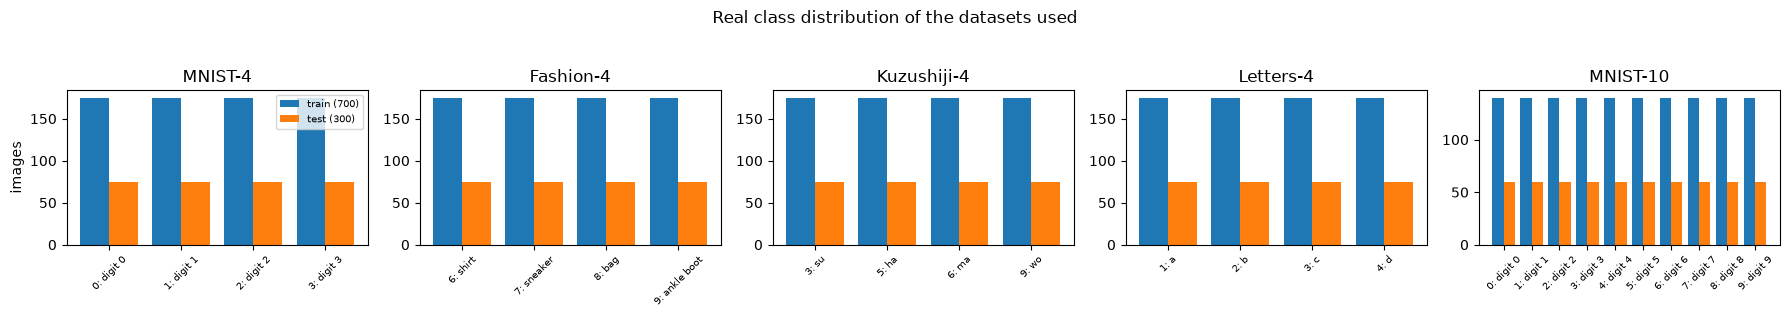

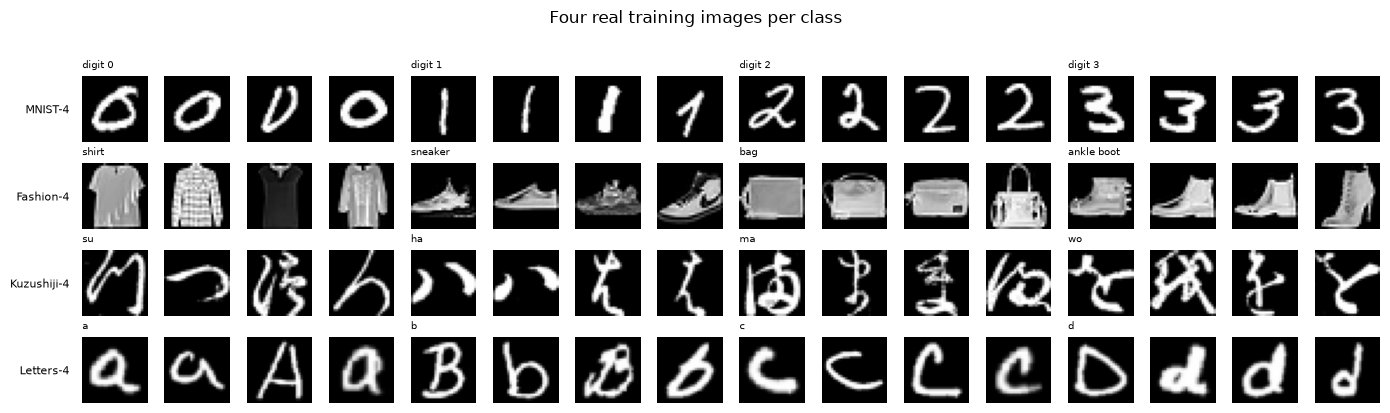

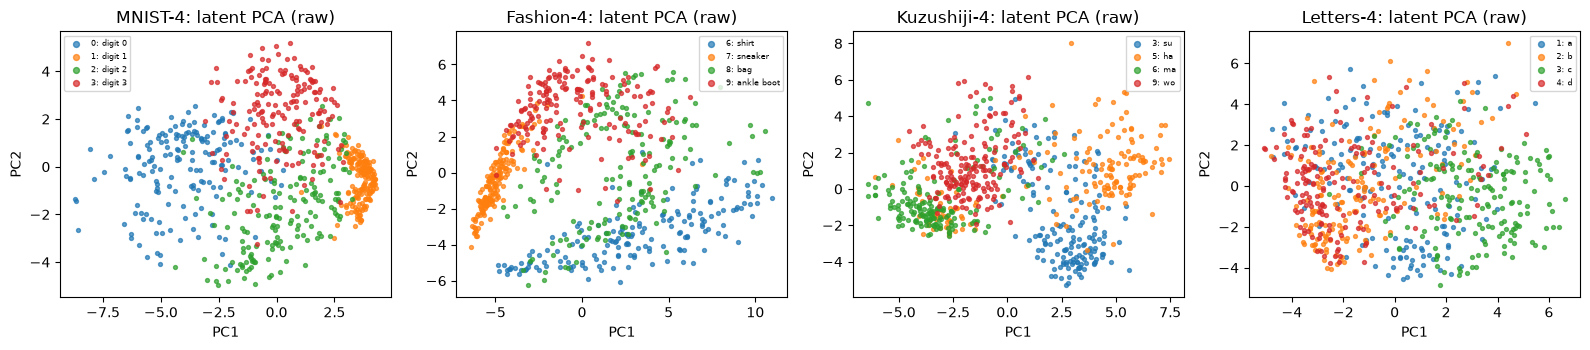

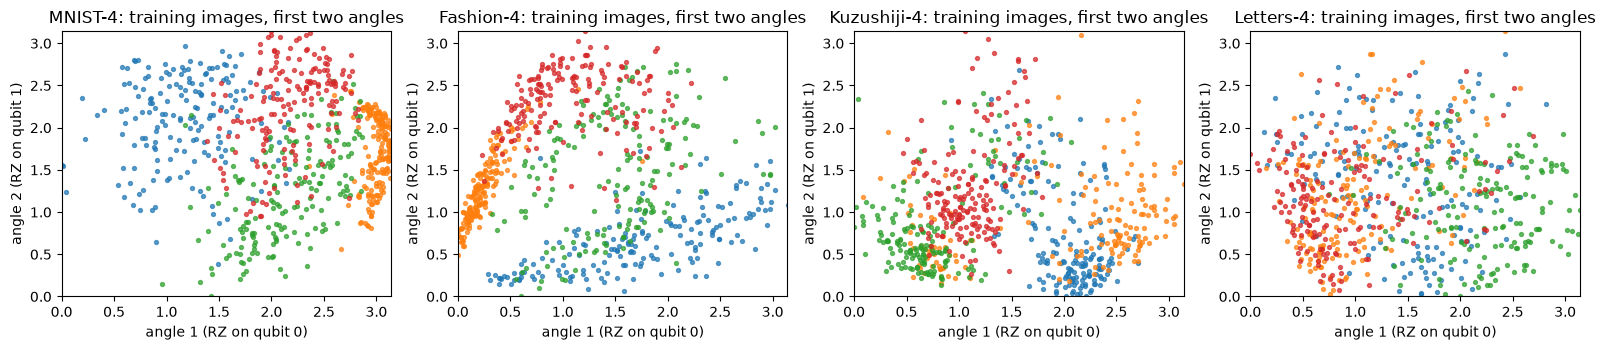

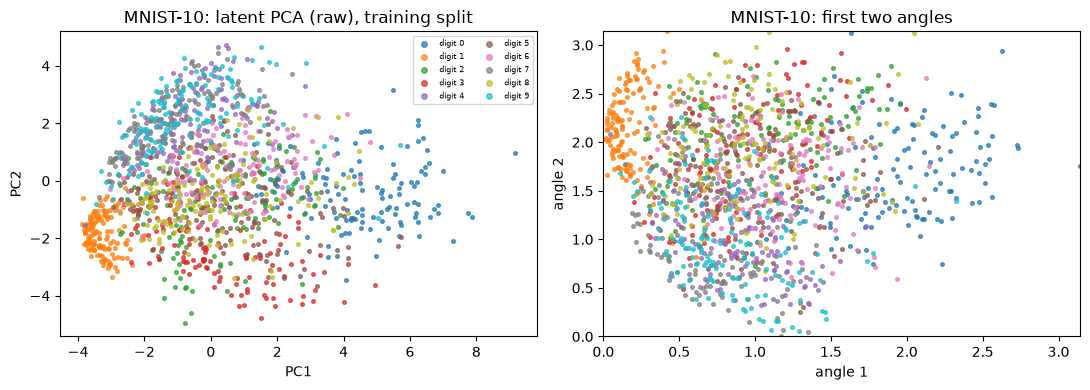

In [6]:
FEATURE_NAMES = [f"latent_{i+1} (angle in [0, pi])" for i in range(N_FEATURES)]
print("Features per image (the d = 8 PCA components, scaled to rotation angles):", FEATURE_NAMES, "\n")
rows = []
for tname, d in DOM.items():
    src, cls = TASKS[tname]; names = CLASS_NAMES[src]
    rows.append(dict(task=tname, source=src, original_labels={int(c): names[c] for c in cls}, images_in_file_subset=len(SUBSETS[src][1]),
                     task_samples=len(d["ytr"]) + len(d["yte"]), train_shape=d["ftr"].shape, test_shape=d["fte"].shape,
                     train_counts=np.bincount(d["ytr"]).tolist(), test_counts=np.bincount(d["yte"]).tolist()))
print(pd.DataFrame(rows).to_string(index=False))
D10 = build_mnist10(SEED, 8)
print(f"\nMNIST-10 (Table VII): train {D10['ftr'].shape}, test {D10['fte'].shape}, original labels 0-9, train counts {np.bincount(D10['ytr']).tolist()}, test counts {np.bincount(D10['yte']).tolist()}")

# ---- class distribution of the real classes (bar chart) ----
fig, axes = plt.subplots(1, 5, figsize=(18, 3.0))
for ax, (tname, d) in zip(axes, list(DOM.items()) + [("MNIST-10", D10)]):
    src = d["src"]; cls = d["orig_classes"]; labs = [f"{c}: {CLASS_NAMES[src][c]}" for c in cls]; x = np.arange(len(cls))
    ax.bar(x - 0.2, np.bincount(d["ytr"]), 0.4, label=f"train ({len(d['ytr'])})"); ax.bar(x + 0.2, np.bincount(d["yte"]), 0.4, label=f"test ({len(d['yte'])})")
    ax.set_xticks(x); ax.set_xticklabels(labs, rotation=45, fontsize=7); ax.set_title(tname)
axes[0].set_ylabel("images"); axes[0].legend(fontsize=7); plt.suptitle("Real class distribution of the datasets used", y=1.04); plt.tight_layout(); plt.show()

# ---- example images ----
fig, axes = plt.subplots(4, 16, figsize=(14, 4.0))
for r_, (tname, d) in enumerate(DOM.items()):
    src = d["src"]; cls = d["orig_classes"]
    for ci in range(4):
        for k, i in enumerate(np.where(d["ytr"] == ci)[0][:4]):
            ax = axes[r_, ci * 4 + k]; ax.imshow(d["img_tr"][i], cmap="gray"); ax.axis("off")
            if k == 0: ax.set_title(CLASS_NAMES[src][cls[ci]], fontsize=7, loc="left")
    axes[r_, 0].text(-6, 14, tname, fontsize=8, ha="right", va="center")
plt.suptitle("Four real training images per class", y=1.02); plt.tight_layout(); plt.show()

# ---- 2-D scatter of real observations coloured by ground-truth label: (1) raw PCA coordinates of the latents, (2) the first two rotation angles ----
cols = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (tname, d) in zip(axes, DOM.items()):
    src = d["src"]; cls = d["orig_classes"]; pca2 = PCA(n_components=2, random_state=SEED).fit(d["ztr"]); P = pca2.transform(d["ztr"])      # PCA fitted on the training split only
    for ci in range(4): ax.scatter(P[d["ytr"] == ci, 0], P[d["ytr"] == ci, 1], s=8, color=cols[ci], alpha=0.7, label=f"{cls[ci]}: {CLASS_NAMES[src][cls[ci]]}")
    ax.set_title(f"{tname}: latent PCA (raw)"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(fontsize=6, markerscale=1.5)
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (tname, d) in zip(axes, DOM.items()):
    src = d["src"]; cls = d["orig_classes"]
    for ci in range(4): ax.scatter(d["ftr"][d["ytr"] == ci, 0], d["ftr"][d["ytr"] == ci, 1], s=8, color=cols[ci], alpha=0.7, label=f"{cls[ci]}: {CLASS_NAMES[src][cls[ci]]}")
    ax.set_title(f"{tname}: training images, first two angles"); ax.set_xlabel("angle 1 (RZ on qubit 0)"); ax.set_ylabel("angle 2 (RZ on qubit 1)"); ax.set_xlim(0, np.pi); ax.set_ylim(0, np.pi)
plt.tight_layout(); plt.show()

# ---- MNIST-10 (Table VII): raw PCA coordinates and the first two angles, coloured by the ten real digits ----
fig, axes = plt.subplots(1, 2, figsize=(11, 4.0)); cm10 = plt.get_cmap("tab10")
P = PCA(n_components=2, random_state=SEED).fit(D10["ztr"]).transform(D10["ztr"])
for c in range(10):
    m = D10["ytr"] == c
    axes[0].scatter(P[m, 0], P[m, 1], s=7, color=cm10(c), alpha=0.7, label=f"digit {c}"); axes[1].scatter(D10["ftr"][m, 0], D10["ftr"][m, 1], s=7, color=cm10(c), alpha=0.7)
axes[0].set_title("MNIST-10: latent PCA (raw), training split"); axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2"); axes[0].legend(fontsize=6, ncol=2, markerscale=1.5)
axes[1].set_title("MNIST-10: first two angles"); axes[1].set_xlabel("angle 1"); axes[1].set_ylabel("angle 2"); axes[1].set_xlim(0, np.pi); axes[1].set_ylim(0, np.pi)
plt.tight_layout(); plt.show()

## 2. The quantum building blocks: one gate list, three executors

A hybrid QNN (Fig. 2 of the paper) is: **angle encoding** (`H` then `RZ(feature)` on each qubit) $\to$ **PQC** (trainable `RX`, `RZ`, controlled-`RX`) $\to$ $\langle Z\rangle$ on every qubit $\to$ **linear layer** with one neuron per class.

To make the notebook honest *and* fast, the circuit is described once as a **gate list** (`enc_ops`, `pqc_ops`). Three executors read that same list:

1. a **PyTorch state-vector simulator** (exact, batched, differentiable): used for all training and evaluation;
2. a **PennyLane QNode** on `default.qubit` (the paper's framework): used for the drawings and as a cross-check;
3. a **Qiskit circuit**: the object that is transpiled and run on the simulated IBM devices in Section 7.

The next section proves that the three agree before anything is trained.

In [7]:
from dataclasses import dataclass, field
CD = torch.complex128

def enc_ops(n, d):
    """Angle encoding. (gate, wires, feature index). d/n rounds: H then RZ(feature) on each qubit; two rounds when a qubit carries two features (4 qubits, d = 8)."""
    assert d % n == 0, "the number of features must be a multiple of the number of qubits"
    ops = []
    for s in range(d // n):
        for q in range(n):
            ops.append(("h", (q,), None)); ops.append(("rz", (q,), s * n + q))
    return ops

def pqc_ops(pqc, n, layers):
    """Parameterised circuit of Sim et al. (2019), circuit number `pqc`, repeated `layers` times. Returns (gate, wires, parameter index) and the parameter count.
    # CHOICE: the paper cites the circuits by number only; the CRX orderings below are reconstructed (see the table at the top)."""
    ops = []; k = [0]
    def rot():
        for q in range(n):
            ops.append(("rx", (q,), k[0])); k[0] += 1
            ops.append(("rz", (q,), k[0])); k[0] += 1
    def crx(c, t):
        ops.append(("crx", (c, t), k[0])); k[0] += 1
    for _ in range(layers):
        if pqc == 1:
            rot()
        elif pqc == 4:
            rot(); [crx(q, q - 1) for q in range(n - 1, 0, -1)]
        elif pqc == 19:
            rot(); [crx(q, (q - 1) % n) for q in range(n - 1, -1, -1)]
        elif pqc == 6:
            rot(); [crx(c, t) for c in range(n) for t in range(n) if c != t]; rot()
        elif pqc == 8:
            rot(); [crx(q, q - 1) for q in range(n - 1, 0, -2)]; rot(); [crx(q, q - 1) for q in range(n - 2, 0, -2)]
        else:
            raise ValueError(pqc)
    return ops, k[0]

@dataclass
class Spec:
    """Architecture of the quantum part of a hybrid QNN."""
    n: int; d: int; pqc: int; layers: int
    def __post_init__(self):
        self.enc = enc_ops(self.n, self.d); self.ops, self.n_params = pqc_ops(self.pqc, self.n, self.layers)
    @property
    def name(self): return f"PQC-{self.pqc}, {self.n} qubits, {self.layers} layer{'s' if self.layers > 1 else ''}, {self.d} features"

# ------------------------------------------------------------------ 1. the PyTorch state-vector simulator (qubit 0 = most significant bit, like PennyLane)
_H = torch.tensor([[1, 1], [1, -1]], dtype=CD) / math.sqrt(2)
def _u_rx(a):
    c, s = torch.cos(a / 2).to(CD), torch.sin(a / 2).to(CD)
    return torch.stack([torch.stack([c, -1j * s]), torch.stack([-1j * s, c])])
def _u_rz(a):
    e = torch.exp(0.5j * a.to(CD)); return torch.diag(torch.stack([e.conj(), e]))
def _u_rz_batch(a):                                    # one angle per sample
    e = torch.exp(0.5j * a.to(CD)); return torch.diag_embed(torch.stack([e.conj(), e], -1))
def _apply1(psi, U, q, n):
    B = psi.shape[0]; s = psi.reshape(B, 2 ** q, 2, 2 ** (n - q - 1))
    out = torch.einsum("ij,bajc->baic", U, s) if U.dim() == 2 else torch.einsum("bij,bajc->baic", U, s)
    return out.reshape(B, -1)

def encode_states(spec, X):
    """Encoded states (B, 2**n) of a batch of feature vectors X (B, d) (fixed, not trainable)."""
    X = torch.as_tensor(X, dtype=torch.float64); B, n = X.shape[0], spec.n
    psi = torch.zeros(B, 2 ** n, dtype=CD); psi[:, 0] = 1
    for g, w, k in spec.enc:
        psi = _apply1(psi, _H if g == "h" else _u_rz_batch(X[:, k]), w[0], n)
    return psi

# The PQC is run as: [fused RZ.RX layer on all qubits: one einsum] and [controlled-RX gates: index/mask arithmetic], to keep the number of tiny tensor operations (the
# bottleneck on a CPU for 4-12 qubits) small. The result is identical to applying the gate list one gate at a time (checked against PennyLane and Qiskit below).
_CRX_AUX = {}
def _crx_aux(n, c, t):
    if (n, c, t) not in _CRX_AUX:
        k = torch.arange(2 ** n); _CRX_AUX[(n, c, t)] = (((k >> (n - 1 - c)) & 1).double(), k ^ (1 << (n - 1 - t)))     # control-bit mask, index with the target bit flipped
    return _CRX_AUX[(n, c, t)]

def compile_plan(spec):
    """Group the gate list into 'rot' segments (RX then RZ on every qubit, fused into one 2x2 matrix per qubit) and single CRX gates."""
    plan, ra, rb = [], {}, {}
    def flush():
        if ra:
            assert sorted(ra) == sorted(rb) == list(range(spec.n)), "plan expects one RX and one RZ per qubit in a rotation layer"
            plan.append(("rot", torch.tensor([ra[q] for q in range(spec.n)]), torch.tensor([rb[q] for q in range(spec.n)]))); ra.clear(); rb.clear()
    for g, w, k in spec.ops:
        if g == "rx":
            if w[0] in ra: flush()                                   # a second layer starts
            ra[w[0]] = k
        elif g == "rz":
            assert w[0] in ra and w[0] not in rb, "plan expects RX before RZ on every qubit"
            rb[w[0]] = k
        else:
            flush(); plan.append(("crx", w[0], w[1], k))
    flush()
    return plan

def _apply_all1(psi, M, n):
    """Apply the 2x2 matrix M[q] on every qubit q in one einsum (state first, so every contraction stays a state-sized matmul)."""
    B = psi.shape[0]; old = "abcdefghijklmnopqrstuvwxy"[:n]; new = "ABCDEFGHIJKLMNOPQRSTUVWXY"[:n]
    eq = "z" + old + "," + ",".join(f"{new[q]}{old[q]}" for q in range(n)) + "->z" + new
    return torch.einsum(eq, psi.reshape((B,) + (2,) * n), *M.unbind(0)).reshape(B, -1)

def run_pqc(spec, psi, theta):
    n = spec.n
    if not hasattr(spec, "plan"): spec.plan = compile_plan(spec)
    ca, sa = torch.cos(theta / 2), torch.sin(theta / 2); e = torch.exp(0.5j * theta.to(CD))
    for step in spec.plan:
        if step[0] == "rot":                          # RZ(b) . RX(a) per qubit = [[e- c, -i e- s], [-i e+ s, e+ c]] with e+ = exp(+i b/2), e- = exp(-i b/2)
            c, s = ca[step[1]].to(CD), sa[step[1]].to(CD); ep = e[step[2]]; em = ep.conj()
            psi = _apply_all1(psi, torch.stack([torch.stack([em * c, -1j * em * s], -1), torch.stack([-1j * ep * s, ep * c], -1)], -2), n)
        else:                                         # CRX(theta) = (1 - m) psi + m (cos psi - i sin psi[target flipped]),  m = control bit
            _, ct, tg, k = step; m, perm = _crx_aux(n, ct, tg)
            psi = ((1 - m) + m * ca[k]) * psi + (m * (-1j * sa[k])) * psi[:, perm]
    return psi

_ZS = {}
def _zsign(n):
    if n not in _ZS:
        k = torch.arange(2 ** n); _ZS[n] = torch.stack([1.0 - 2.0 * ((k >> (n - 1 - q)) & 1).double() for q in range(n)], 1)
    return _ZS[n]

def pqc_z(spec, psi_enc, theta):
    """<Z> of every qubit after the PQC: (B, n)."""
    psi = run_pqc(spec, psi_enc, theta); return (psi.real ** 2 + psi.imag ** 2) @ _zsign(spec.n)

def pqc_z_nograd(spec, psi_enc, theta, chunk=None):
    chunk = chunk or max(1, 2 ** 21 // 2 ** spec.n)
    with torch.no_grad():
        return torch.cat([pqc_z(spec, psi_enc[i:i + chunk], theta) for i in range(0, len(psi_enc), chunk)])

# ------------------------------------------------------------------ 2. the PennyLane QNode (default.qubit, the paper's framework)
def make_qnode(spec):
    @qml.qnode(qml.device("default.qubit", wires=spec.n))
    def circuit(x, theta):
        for g, w, k in spec.enc:
            if g == "h": qml.Hadamard(wires=w[0])
            else: qml.RZ(x[k], wires=w[0])
        qml.Barrier(wires=range(spec.n))                 # only a visual separator between encoding and PQC in the drawings
        for g, w, k in spec.ops:
            if g == "rx": qml.RX(theta[k], wires=w[0])
            elif g == "rz": qml.RZ(theta[k], wires=w[0])
            else: qml.CRX(theta[k], wires=list(w))
        return [qml.expval(qml.PauliZ(q)) for q in range(spec.n)]
    return circuit

# ------------------------------------------------------------------ 3. the Qiskit circuit (what is transpiled for the simulated IBM devices)
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, SparsePauliOp
def qiskit_circuit(spec, x, theta, barrier=True):
    qc = QuantumCircuit(spec.n)
    for g, w, k in spec.enc:
        if g == "h": qc.h(w[0])
        else: qc.rz(x[k], w[0])
    if barrier: qc.barrier()
    for g, w, k in spec.ops:
        if g == "rx": qc.rx(float(theta[k]), w[0])
        elif g == "rz": qc.rz(float(theta[k]), w[0])
        else: qc.crx(float(theta[k]), w[0], w[1])
    return qc

def z_qiskit(spec, x, theta):
    sv = Statevector(qiskit_circuit(spec, [float(v) for v in x], theta, barrier=False))
    return np.array([sv.expectation_value(SparsePauliOp("I" * (spec.n - 1 - q) + "Z" + "I" * q)).real for q in range(spec.n)])    # Qiskit is little-endian
print("gate-list executors defined: torch simulator, PennyLane QNode, Qiskit circuit")

gate-list executors defined: torch simulator, PennyLane QNode, Qiskit circuit


## Quantum Circuit Architecture

Every gate-based model that is trained or evaluated in this notebook is one of the architectures below (the paper names the PQC numbers; the details are reconstructed, see the table at the top):

| Use | Architecture |
|---|---|
| Tables I, II / Figs. 5, 6 | PQC-4, 4 qubits, 1 layer, 2 features per qubit |
| Tables III-V / Figs. 7, 8 and Section 10 | PQC-19, 8 qubits, 2 layers, 1 feature per qubit |
| Table VI (real hardware, needs a token) | PQC-1, 4 qubits, 2 layers |
| Fig. 9 | PQC-8, 8 qubits, 2 layers (baseline) and PQC-6, 4 qubits, 2 layers (STIQ members) |
| Table VII | PQC-19, 2 layers, one feature per qubit, widths from `SCALE_QUBITS` |

**Check first, draw second.** The cell below compares, for every distinct architecture, the $\langle Z\rangle$ vector from the PyTorch simulator that does all the training, from the PennyLane QNode and from the Qiskit circuit (random inputs in $[0,\pi]$, random angles in $[0,2\pi)$) and asserts that the largest difference is below $10^{-10}$.
Then each architecture is **drawn from the PennyLane QNode** that was just verified, with qubit count, depth and number of trainable parameters. The two cloud providers of a STIQ pair run the **same architecture with different trained angles**; their trained circuits are drawn in Section 5.

In [8]:
ARCH_USES = {   # distinct architectures that appear in the experiments below
    "Tables I-II (PQC-4)":        Spec(4, 8, 4, 1),
    "Tables III-V, Sec. 10 (PQC-19)": Spec(8, 8, 19, 2),
    "Table VI (PQC-1)":           Spec(4, 8, 1, 2),
    "Fig. 9 baseline (PQC-8)":    Spec(8, 8, 8, 2),
    "Fig. 9 STIQ member (PQC-6)": Spec(4, 8, 6, 2),
}
for nq in SCALE_QUBITS:
    if nq != 8: ARCH_USES[f"Table VII, {nq} qubits (PQC-19)"] = Spec(nq, nq, 19, 2)

rr = np.random.default_rng(0); rows = []
for use, sp in ARCH_USES.items():
    x = rr.uniform(0, np.pi, sp.d); th = rr.uniform(0, 2 * np.pi, sp.n_params)
    z_t = pqc_z(sp, encode_states(sp, x[None]), torch.tensor(th))[0].numpy()
    z_p = np.array([float(v) for v in make_qnode(sp)(x, th)])
    z_q = z_qiskit(sp, x, th)
    qc = qiskit_circuit(sp, x, th, barrier=False)
    rows.append(dict(architecture=use, qubits=sp.n, features=sp.d, layers=sp.layers, trainable_angles=sp.n_params, depth=qc.depth(), gates=sum(qc.count_ops().values()),
                     two_qubit_gates=sum(v for k, v in qc.count_ops().items() if k == "crx"),
                     max_diff_torch_vs_pennylane=np.abs(z_t - z_p).max(), max_diff_torch_vs_qiskit=np.abs(z_t - z_q).max()))
chk = pd.DataFrame(rows)
print(chk.to_string(index=False, float_format=lambda v: f"{v:.1e}" if abs(v) < 1e-3 else f"{v:g}"))
assert chk.max_diff_torch_vs_pennylane.max() < 1e-10 and chk.max_diff_torch_vs_qiskit.max() < 1e-10, "simulator disagrees with PennyLane / Qiskit"
print(f"\nOK: the PyTorch simulator used for training equals the PennyLane QNode and the Qiskit circuit for all {len(ARCH_USES)} architectures, max difference {max(chk.max_diff_torch_vs_pennylane.max(), chk.max_diff_torch_vs_qiskit.max()):.1e}")
print("(depth and gate counts are those of the logical circuit without barriers; each controlled-RX is one gate here and two CNOTs on a device)")

                  architecture  qubits  features  layers  trainable_angles  depth  gates  two_qubit_gates  max_diff_torch_vs_pennylane  max_diff_torch_vs_qiskit
           Tables I-II (PQC-4)       4         8       1                11      9     27                3                      2.8e-16                   3.9e-16
Tables III-V, Sec. 10 (PQC-19)       8         8       2                48     22     64               16                      6.1e-16                   6.1e-16
              Table VI (PQC-1)       4         8       2                16      8     32                0                      4.4e-16                   6.7e-16
       Fig. 9 baseline (PQC-8)       8         8       2                78     14     94               14                      6.7e-16                   8.9e-16
    Fig. 9 STIQ member (PQC-6)       4         8       2                56     33     72               24                      3.9e-16                   3.3e-16
  Table VII, 4 qubits (PQC-19)    

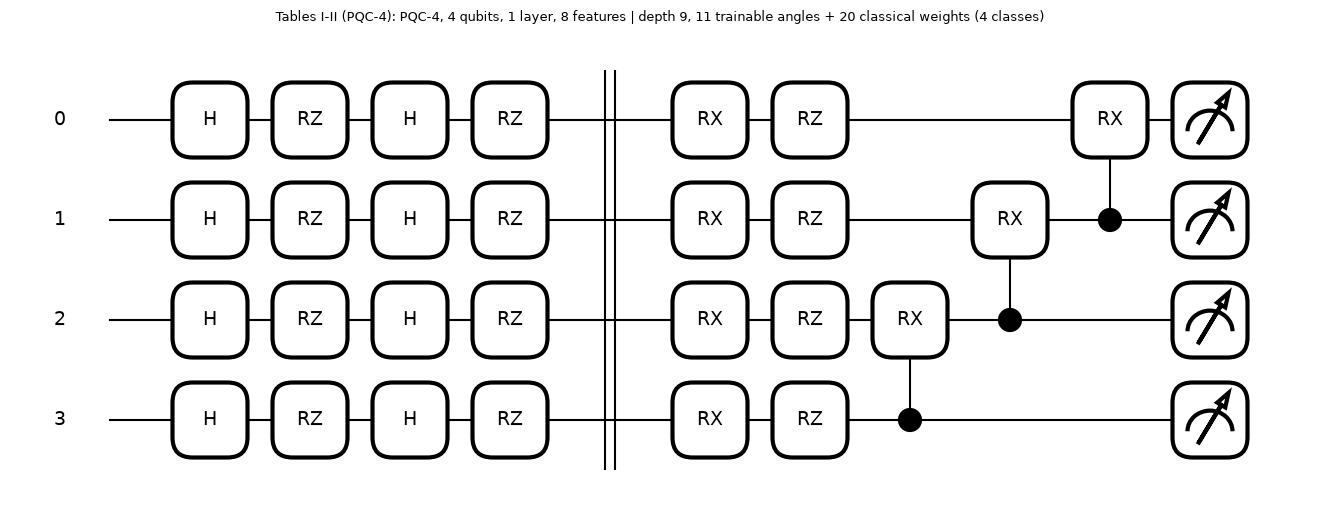

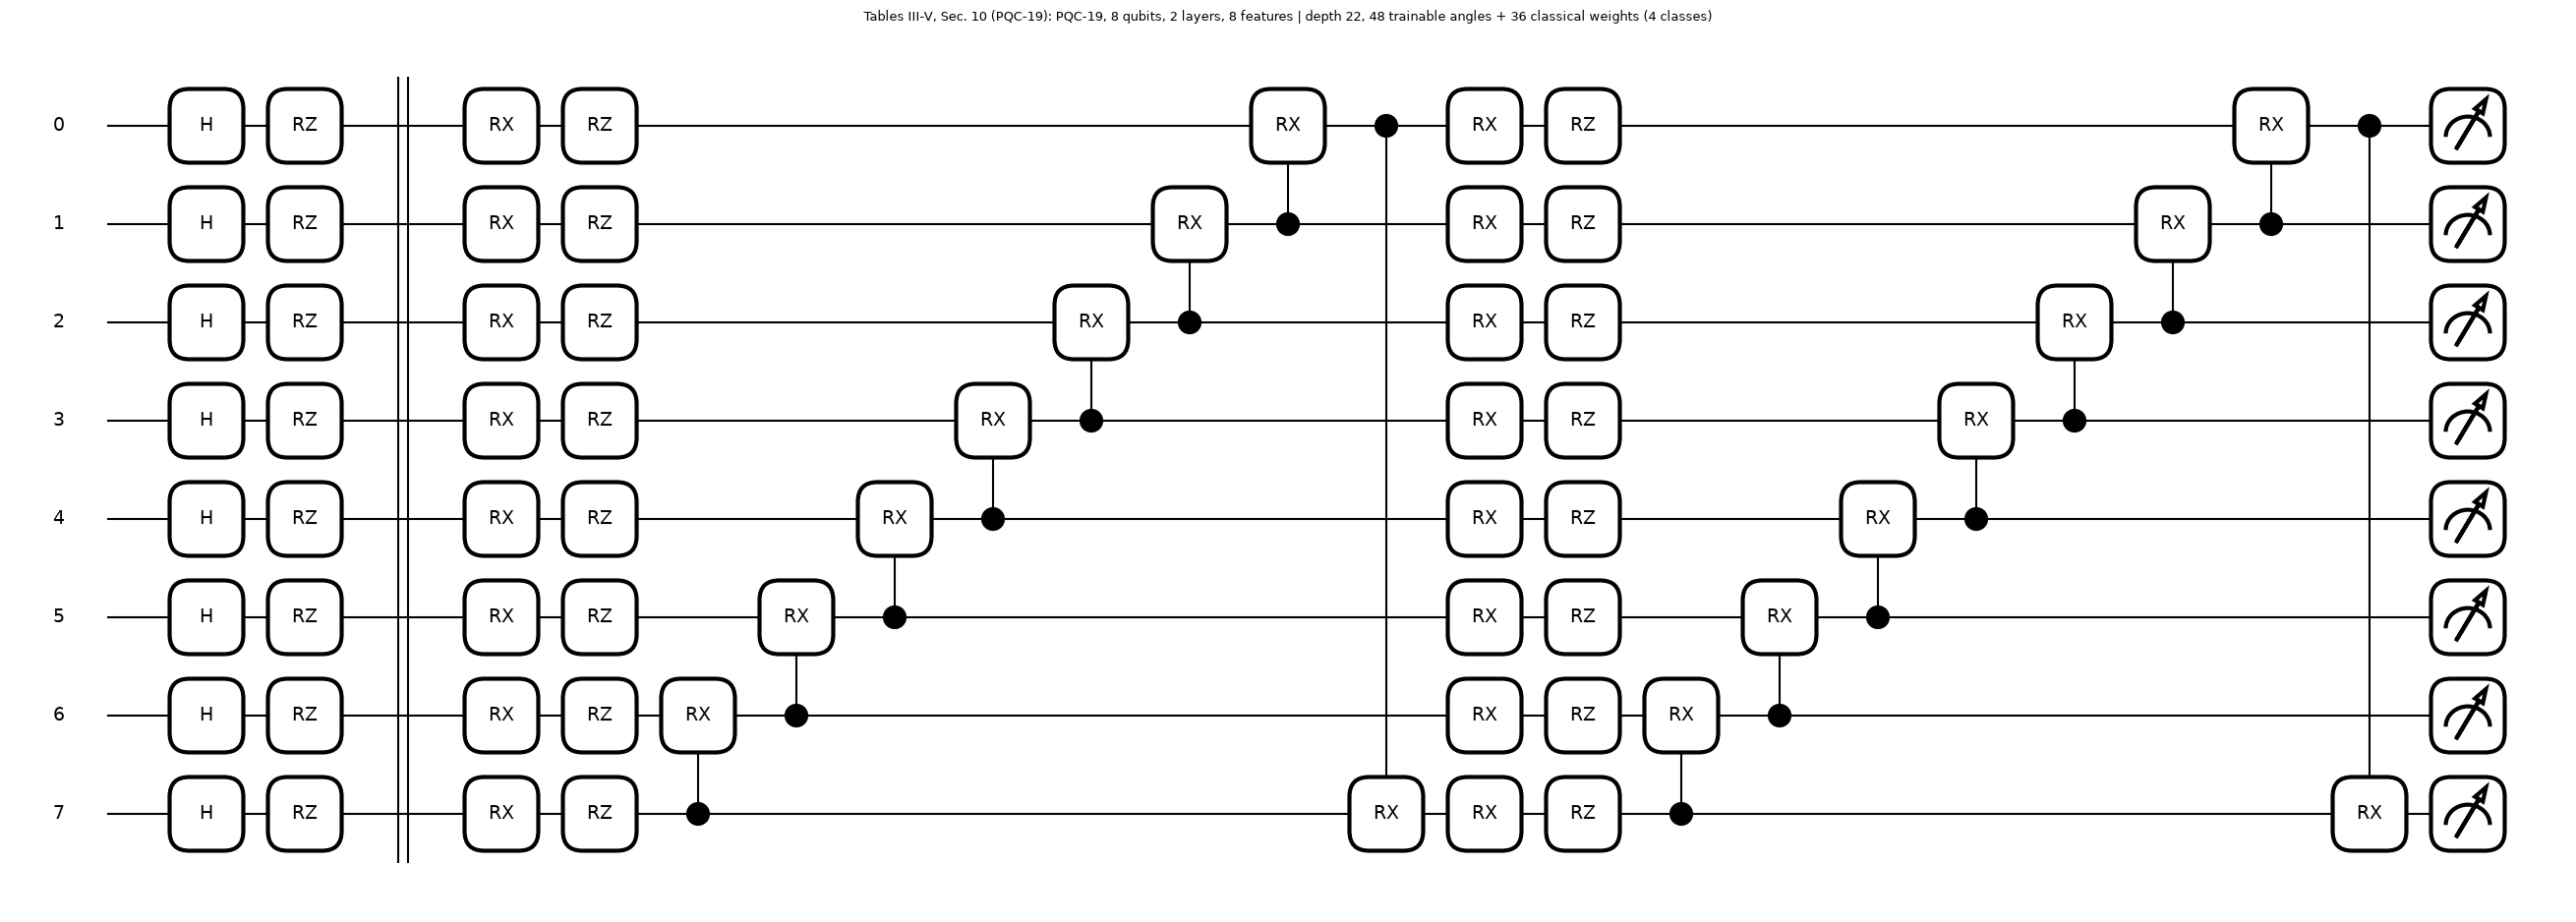

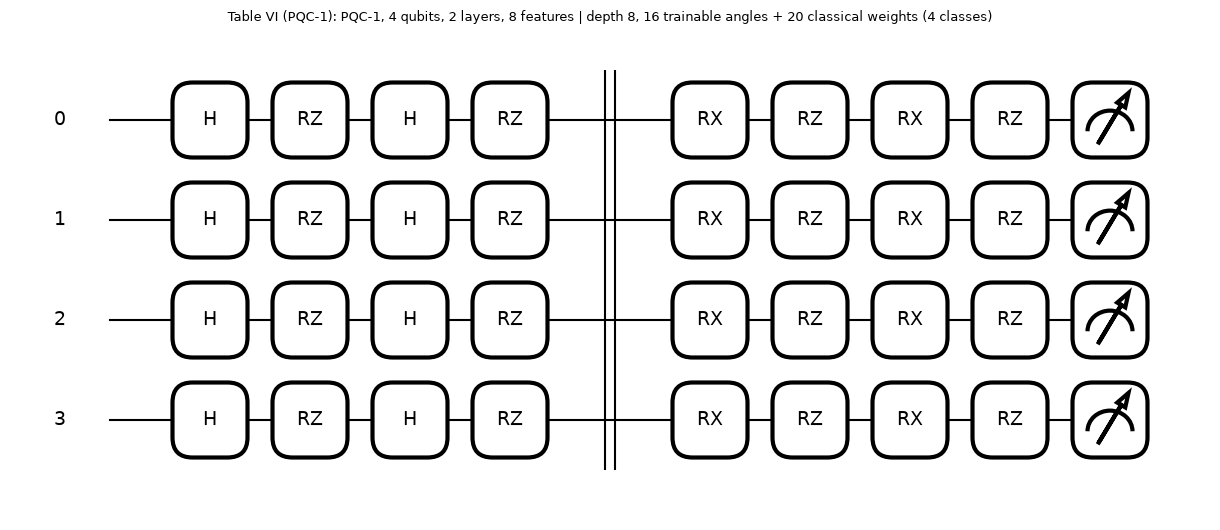

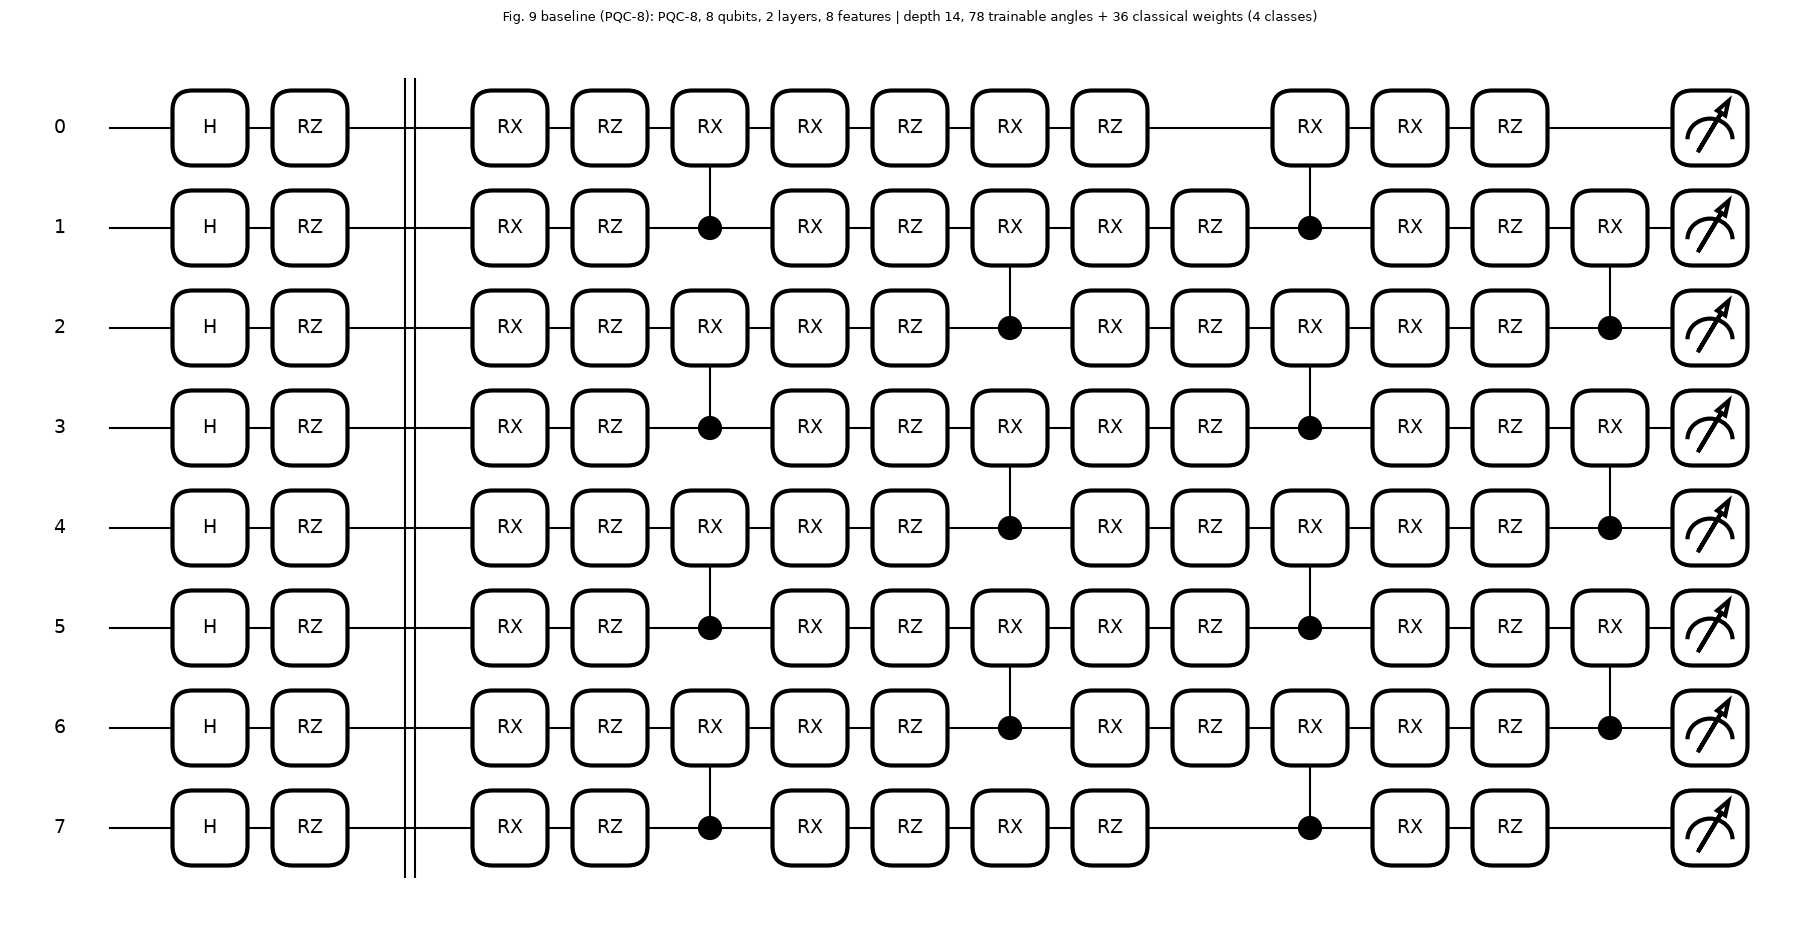

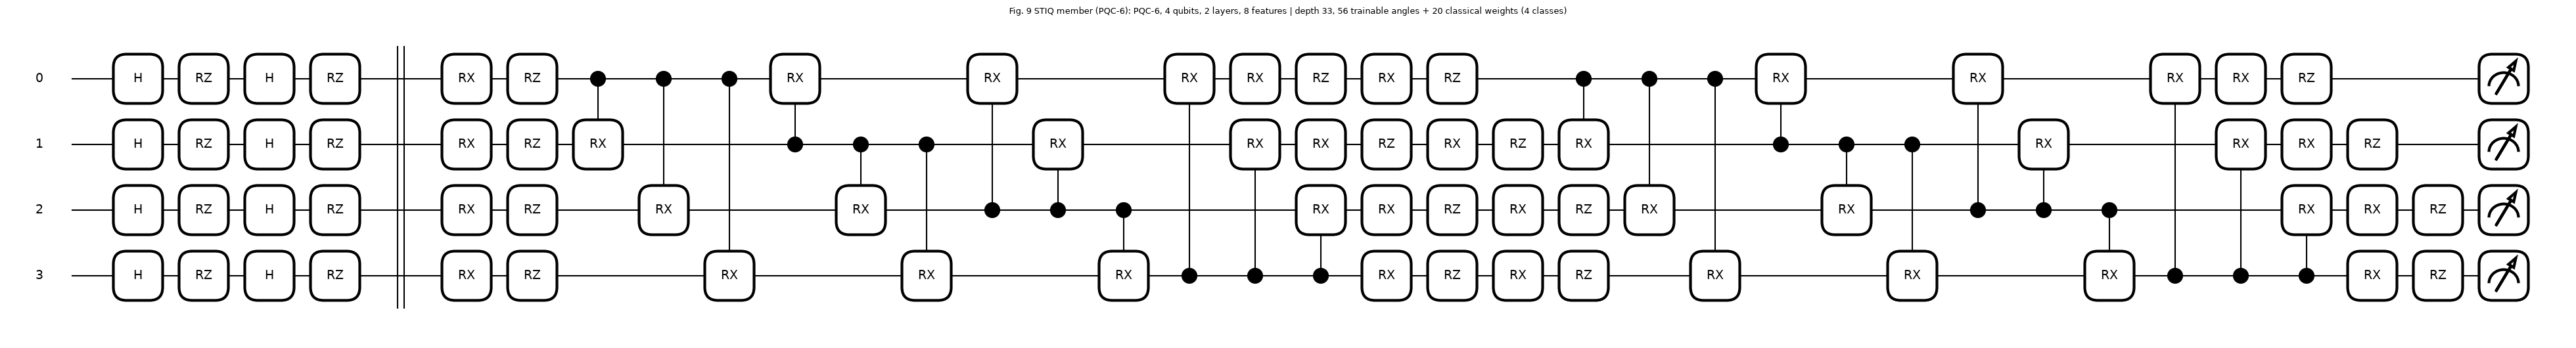

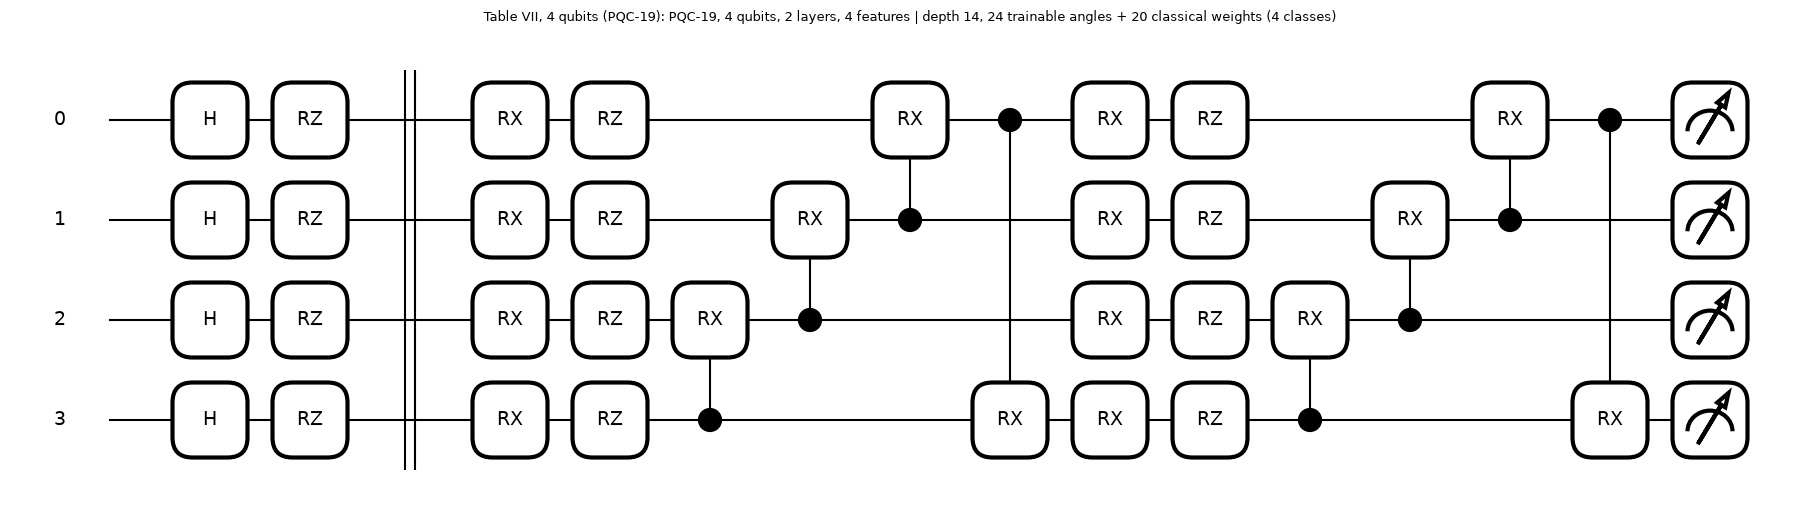

In [9]:
# Draw the circuit that is actually executed: the PennyLane QNode of every distinct architecture (encoding | barrier | PQC | Pauli-Z read-out).
# The classical linear layer (n -> classes) after the read-out is not part of the quantum circuit.
for use, sp in ARCH_USES.items():
    x = np.linspace(0.3, 2.8, sp.d); th = np.linspace(0.1, 6.0, sp.n_params)
    fig, ax = qml.draw_mpl(make_qnode(sp), decimals=None, style="black_white")(x, th)
    fig.suptitle(f"{use}: {sp.name} | depth {qiskit_circuit(sp, x, th, barrier=False).depth()}, {sp.n_params} trainable angles + {sp.n * 4 + 4} classical weights (4 classes)", fontsize=9, y=1.02)
    plt.show()

**Assumptions where the paper omits circuit details.** (i) Circuit numbers refer to Sim et al. (2019); we rebuilt the gate lists from that paper's description, so the *order* of the controlled-`RX` gates may differ from the original. (ii) The paper's Fig. 2 shows `H` then `RZ(f)` on a qubit; for two features per qubit we repeat the `H`, `RZ` round. (iii) "Layers" repeat the whole block with fresh angles. (iv) The classical layer after the read-out belongs to the hosted model; a provider is assumed to see it (white-box).

## 3. Training machinery: baseline QNN and the STIQ pair

* `Hybrid`: quantum angles $\theta$ (random in $[0,2\pi)$) + linear layer $W, b$; `logits = <Z> @ W + b`.
* **Baseline**: one `Hybrid`, loss = cross-entropy, Adam.
* **STIQ**: two `Hybrid` models $U_1, U_2$; $y_1$, $y_2$ their logits; $A$ = mean; loss $L_T = \text{CE}(A(y_1,y_2), \hat y) + \lambda\, D(y_1,y_2)$ (Eq. 1); one Adam optimiser per model.
* **Gradients**: exact back-propagation through the simulator (the paper's noiseless simulations use adjoint gradients, also exact), or **SPSA** for the noisy / large runs (Table VII).
* After every epoch we log the accuracy and cross-entropy of the baseline, of QNN-1, of QNN-2 and of the combined output on train and test data.

In [10]:
class Hybrid:
    """Hybrid QNN: encoded state -> PQC -> <Z> of every qubit -> linear layer (n -> classes)."""
    def __init__(self, spec, n_cls, seed):
        g = torch.Generator().manual_seed(int(seed)); self.spec, self.n_cls = spec, n_cls
        self.theta = (torch.rand(spec.n_params, generator=g, dtype=torch.float64) * 2 * math.pi).requires_grad_()      # CHOICE: random circuit weights in [0, 2 pi)
        bound = 1 / math.sqrt(spec.n)                                                                                    # torch.nn.Linear's default initialisation
        self.W = ((torch.rand(spec.n, n_cls, generator=g, dtype=torch.float64) * 2 - 1) * bound).requires_grad_()
        self.b = ((torch.rand(n_cls, generator=g, dtype=torch.float64) * 2 - 1) * bound).requires_grad_()
    def params(self): return [self.theta, self.W, self.b]
    def logits_from_z(self, z): return z @ self.W + self.b
    def logits(self, psi_enc, theta=None): return self.logits_from_z(pqc_z(self.spec, psi_enc, self.theta if theta is None else theta))
    @torch.no_grad()
    def predict_logits(self, psi_enc): return self.logits_from_z(pqc_z_nograd(self.spec, psi_enc, self.theta))
    def clone_params(self):
        return dict(theta=self.theta.detach().clone(), W=self.W.detach().clone(), b=self.b.detach().clone())
    def load(self, p):
        with torch.no_grad(): self.theta.copy_(p["theta"]); self.W.copy_(p["W"]); self.b.copy_(p["b"])

def divergence(a, b, kind):
    """D(y1, y2): LOW when the two output vectors differ (the training minimises it)."""
    if kind == "cos": return F.cosine_similarity(a, b, dim=1).mean()               # CosineSimilarity: high for identical, low for dissimilar vectors
    if kind == "l1":  return -(a - b).abs().sum(1).mean()                           # CHOICE: sign flipped so that a large distance gives a low value
    if kind == "l2":  return -((a - b) ** 2).sum(1).mean()
    raise ValueError(kind)

def total_loss(logits, y, lam=0.0, div="cos", space="logits"):
    """One model: cross-entropy. Two models: L_T = C(A(y1, y2), y) + lam * D(y1, y2) with A = mean (Eq. 1). Returns (L_T, L_C, L_D)."""
    if len(logits) == 1:
        lc = F.cross_entropy(logits[0], y); return lc, lc, torch.zeros(())
    a, b = (logits[0], logits[1]) if space == "logits" else (F.softmax(logits[0], 1), F.softmax(logits[1], 1))
    agg = (a + b) / 2
    lc = F.cross_entropy(agg, y) if space == "logits" else F.nll_loss(torch.log(agg + 1e-12), y)
    ld = divergence(a, b, div)
    return lc + lam * ld, lc, ld

@torch.no_grad()
def evaluate(models, psis, y, space="logits"):
    """Accuracy and cross-entropy of every member and (for a pair) of the aggregated output. y: LongTensor."""
    ls = [m.predict_logits(p) for m, p in zip(models, psis)]
    out = {f"acc_{i}": float((l.argmax(1) == y).double().mean()) for i, l in enumerate(ls)}
    out.update({f"loss_{i}": float(F.cross_entropy(l, y)) for i, l in enumerate(ls)})
    if len(ls) == 2:
        agg = (ls[0] + ls[1]) / 2 if space == "logits" else (F.softmax(ls[0], 1) + F.softmax(ls[1], 1)) / 2
        out["acc_comb"] = float((agg.argmax(1) == y).double().mean())
        out["loss_comb"] = float(F.cross_entropy(agg, y)) if space == "logits" else float(F.nll_loss(torch.log(agg + 1e-12), y))
    return out

def train(specs, dom, lam=0.3, div="cos", epochs=30, seed=42, space="logits", grad="backprop", spsa_c=None, tag=""):
    """Train one model (baseline, len(specs) == 1) or a STIQ pair (len == 2) on dom (a task dict). Returns models, per-epoch history and wall-clock seconds.
    grad = 'backprop' (exact) or 'spsa' (two circuit evaluations per model and step, Rademacher perturbation)."""
    spsa_c = SPSA_C if spsa_c is None else spsa_c
    n_cls = len(dom["classes"]); models = [Hybrid(sp, n_cls, seed * 100 + i) for i, sp in enumerate(specs)]
    Ptr = [encode_states(sp, dom["ftr"]) for sp in specs]; Pte = [encode_states(sp, dom["fte"]) for sp in specs]
    ytr, yte = torch.as_tensor(dom["ytr"]), torch.as_tensor(dom["yte"])
    opts = [torch.optim.Adam(m.params(), lr=LR) for m in models]
    r = np.random.default_rng(seed); gt = torch.Generator().manual_seed(int(seed) + 7); N = len(ytr); hist = []; t0 = time.time()
    def log(ep):
        te = evaluate(models, Pte, yte, space); tr = evaluate(models, Ptr, ytr, space)
        hist.append(dict(epoch=ep, **{f"test_{k}": v for k, v in te.items()}, **{f"train_{k}": v for k, v in tr.items()}))
    log(0)
    for ep in range(1, epochs + 1):
        perm = r.permutation(N)
        for s in range(0, N, BATCH):
            idx = torch.as_tensor(perm[s:s + BATCH]); yb = ytr[idx]
            for o in opts: o.zero_grad()
            if grad == "backprop":
                loss, _, _ = total_loss([m.logits(P[idx]) for m, P in zip(models, Ptr)], yb, lam, div, space); loss.backward()
            else:   # SPSA: circuit angles by finite differences along a random +-1 direction, linear layers by exact gradients at the mid-point output
                zp, zm, zmid, deltas = [], [], [], []
                with torch.no_grad():
                    for m, P in zip(models, Ptr):
                        dl = (torch.randint(0, 2, m.theta.shape, generator=gt).double() * 2 - 1); deltas.append(dl)
                        a = pqc_z(m.spec, P[idx], m.theta + spsa_c * dl); b = pqc_z(m.spec, P[idx], m.theta - spsa_c * dl)
                        zp.append(a); zm.append(b); zmid.append((a + b) / 2)        # CHOICE: z(theta) is approximated by the mean of the two perturbed outputs (error O(c^2))
                    for i, m in enumerate(models):
                        def L(zi):
                            lg = [mm.logits_from_z(zmid[j] if j != i else zi) for j, mm in enumerate(models)]
                            return float(total_loss(lg, yb, lam, div, space)[0])
                        m.theta.grad = torch.tensor((L(zp[i]) - L(zm[i])) / (2 * spsa_c), dtype=torch.float64) * deltas[i]
                loss, _, _ = total_loss([m.logits_from_z(z) for m, z in zip(models, zmid)], yb, lam, div, space)
                grads = torch.autograd.grad(loss, [p for m in models for p in (m.W, m.b)])
                for j, m in enumerate(models): m.W.grad, m.b.grad = grads[2 * j], grads[2 * j + 1]
            for o in opts: o.step()
        log(ep)
    return dict(models=models, hist=pd.DataFrame(hist), seconds=time.time() - t0, specs=specs, tag=tag, lam=lam, div=div, space=space, seed=seed)

def final_row(res, **extra):
    """Last-epoch test metrics of a trained model or pair, as percentages."""
    h = res["hist"].iloc[-1]; row = dict(extra)
    if len(res["models"]) == 1: row.update(acc=100 * h["test_acc_0"], loss=h["test_loss_0"])
    else: row.update(acc1=100 * h["test_acc_0"], acc2=100 * h["test_acc_1"], acc_comb=100 * h["test_acc_comb"], loss1=h["test_loss_0"], loss2=h["test_loss_1"], loss_comb=h["test_loss_comb"])
    row["seconds"] = res["seconds"]; return row

## 4. Classical baselines on exactly the same inputs

The paper compares STIQ with an unprotected QNN only. To see how much the quantum part contributes, we also train classical models on the **same 8 rotation angles** the QNN receives: an RBF support-vector machine, a random forest and a small multi-layer perceptron. These numbers are context, not part of the paper's claims.

In [11]:
def classical_baselines(dom, seed):
    out = {}
    for name, mk in {"SVC (rbf)": lambda: SVC(kernel="rbf", C=1.0, random_state=seed),
                     "RandomForest": lambda: RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=1),
                     "MLP (32 hidden)": lambda: MLPClassifier((32,), max_iter=400, random_state=seed)}.items():
        out[name] = 100 * mk().fit(dom["ftr"], dom["ytr"]).score(dom["fte"], dom["yte"])
    return out
CLASSICAL = {}
for seed in SEEDS:
    for t, d in build_domain(seed).items(): CLASSICAL[(t, seed)] = classical_baselines(d, seed)
tab = pd.DataFrame({t: pd.DataFrame([CLASSICAL[(t, s)] for s in SEEDS]).mean() for t in TASKS}).T
print("Classical test accuracy (%) on the same 8 angles (mean over seeds):"); print(tab.round(1).to_string())

Classical test accuracy (%) on the same 8 angles (mean over seeds):
             SVC (rbf)  RandomForest  MLP (32 hidden)
MNIST-4           96.0          95.0             94.7
Fashion-4         94.7          93.0             92.3
Kuzushiji-4       90.0          88.3             84.3
Letters-4         83.3          81.3             82.3


## 5. STIQ against the unprotected baseline: Tables III and IV, Fig. 7

Setting of Sec. V-B "Different Datasets": 8-qubit, 2-layer PQC-19, cosine similarity as $D$, $\lambda = 0.3$, Adam with learning rate 0.01, batch 32. Both the baseline and the STIQ pair are trained from random weights on the 700 training images and scored on the 300 test images;
the *obfuscation* of Table IV is the ratio $\text{mean}(\text{QNN-1},\text{QNN-2}) / \text{baseline}$ (for accuracy: low = good obfuscation), the *performance $\Delta$* is $\text{combined}/\text{baseline}$ (1.0 = nothing lost).

In [12]:
SPEC_MAIN = ARCH_USES["Tables III-V, Sec. 10 (PQC-19)"]
MAIN = {}       # (task, seed) -> dict(base=..., stiq=...)
t0 = time.time()
for seed in SEEDS:
    for t, d in build_domain(seed).items():
        base = train([SPEC_MAIN], d, epochs=EPOCHS_MAIN, seed=seed, tag=f"baseline {t}")
        stiq = train([SPEC_MAIN, SPEC_MAIN], d, lam=LAMBDA, div="cos", epochs=EPOCHS_MAIN, seed=seed, tag=f"STIQ {t}")
        MAIN[(t, seed)] = dict(base=base, stiq=stiq)
        print(f"seed {seed} {t:12s}: baseline {100*base['hist'].iloc[-1]['test_acc_0']:.1f} % ({base['seconds']:.0f} s) | STIQ QNN-1 {100*stiq['hist'].iloc[-1]['test_acc_0']:.1f} %, QNN-2 {100*stiq['hist'].iloc[-1]['test_acc_1']:.1f} %, combined {100*stiq['hist'].iloc[-1]['test_acc_comb']:.1f} % ({stiq['seconds']:.0f} s)", flush=True)
print(f"done in {time.time() - t0:.0f} s")

seed 42 MNIST-4     : baseline 95.3 % (63 s) | STIQ QNN-1 53.3 %, QNN-2 25.0 %, combined 93.3 % (135 s)


seed 42 Fashion-4   : baseline 92.3 % (86 s) | STIQ QNN-1 35.7 %, QNN-2 26.0 %, combined 92.3 % (182 s)


seed 42 Kuzushiji-4 : baseline 84.0 % (65 s) | STIQ QNN-1 43.3 %, QNN-2 28.3 %, combined 84.0 % (130 s)


seed 42 Letters-4   : baseline 80.0 % (60 s) | STIQ QNN-1 25.0 %, QNN-2 31.3 %, combined 81.0 % (116 s)


done in 849 s


In [13]:
PAPER_T3 = {   # Table III: (baseline acc, loss, QNN-1 acc, loss, QNN-2 acc, loss, combined acc, loss)
    "MNIST-4": (98.3, 0.099, 22.6, 5.346, 37.6, 2.915, 98.3, 0.137), "Fashion-4": (95.6, 0.183, 36.6, 4.158, 42.6, 3.685, 95.9, 0.224),
    "Kuzushiji-4": (88.3, 0.398, 43.3, 4.388, 27.3, 5.718, 89.3, 0.405), "Letters-4": (92.3, 0.325, 30.6, 5.430, 27.0, 5.310, 93.3, 0.375)}
rows = []
for t in TASKS:
    per = [dict(base=final_row(MAIN[(t, s)]["base"]), stiq=final_row(MAIN[(t, s)]["stiq"])) for s in SEEDS]
    g = lambda f: np.array([f(p) for p in per])
    ms = lambda a: f"{a.mean():.1f} +- {a.std():.1f}" if len(a) > 1 else f"{a.mean():.1f}"
    rows.append({"dataset": t, "baseline acc": ms(g(lambda p: p["base"]["acc"])), "QNN-1 acc": ms(g(lambda p: p["stiq"]["acc1"])), "QNN-2 acc": ms(g(lambda p: p["stiq"]["acc2"])),
                 "combined acc": ms(g(lambda p: p["stiq"]["acc_comb"])), "baseline loss": f"{g(lambda p: p['base']['loss']).mean():.3f}", "QNN-1 loss": f"{g(lambda p: p['stiq']['loss1']).mean():.2f}",
                 "QNN-2 loss": f"{g(lambda p: p['stiq']['loss2']).mean():.2f}", "combined loss": f"{g(lambda p: p['stiq']['loss_comb']).mean():.3f}"})
print(f"This notebook, Table III (test accuracy in percent, test cross-entropy; mean +- std over seeds {SEEDS}):"); print(pd.DataFrame(rows).to_string(index=False))
print("\nPaper, Table III:"); print(pd.DataFrame([{"dataset": t, "baseline acc": v[0], "QNN-1 acc": v[2], "QNN-2 acc": v[4], "combined acc": v[6], "baseline loss": v[1], "QNN-1 loss": v[3], "QNN-2 loss": v[5], "combined loss": v[7]} for t, v in PAPER_T3.items()]).to_string(index=False))

# ---- Table IV: obfuscation = mean(QNN-1, QNN-2) / baseline, performance delta = combined / baseline ----
rows4 = []; PAPER_T4 = {"MNIST-4": (0.3, 41.3, 1.0, 1.37), "Fashion-4": (0.4, 21.4, 1.0, 1.22), "Kuzushiji-4": (0.4, 12.7, 1.01, 1.02), "Letters-4": (0.3, 16.5, 1.01, 1.15)}
T4 = {}
for t in TASKS:
    v = []
    for s in SEEDS:
        b, st = final_row(MAIN[(t, s)]["base"]), final_row(MAIN[(t, s)]["stiq"])
        v.append(((st["acc1"] + st["acc2"]) / 2 / b["acc"], (st["loss1"] + st["loss2"]) / 2 / b["loss"], st["acc_comb"] / b["acc"], st["loss_comb"] / b["loss"]))
    v = np.mean(v, axis=0); T4[t] = v; p = PAPER_T4[t]
    rows4.append({"dataset": t, "obf. acc (nb / paper)": f"{v[0]:.2f}x / {p[0]}x", "obf. loss (nb / paper)": f"{v[1]:.1f}x / {p[1]}x", "perf. acc (nb / paper)": f"{v[2]:.2f}x / {p[2]}x", "perf. loss (nb / paper)": f"{v[3]:.2f}x / {p[3]}x"})
print("\nTable IV (ratios to the baseline):"); print(pd.DataFrame(rows4).to_string(index=False))

This notebook, Table III (test accuracy in percent, test cross-entropy; mean +- std over seeds [42]):
    dataset baseline acc QNN-1 acc QNN-2 acc combined acc baseline loss QNN-1 loss QNN-2 loss combined loss
    MNIST-4         95.3      53.3      25.0         93.3         0.187       2.84       7.27         0.261
  Fashion-4         92.3      35.7      26.0         92.3         0.244       3.09       5.23         0.263
Kuzushiji-4         84.0      43.3      28.3         84.0         0.435       3.44       5.66         0.449
  Letters-4         80.0      25.0      31.3         81.0         0.543       5.60       3.11         0.531

Paper, Table III:
    dataset  baseline acc  QNN-1 acc  QNN-2 acc  combined acc  baseline loss  QNN-1 loss  QNN-2 loss  combined loss
    MNIST-4          98.3       22.6       37.6          98.3          0.099       5.346       2.915          0.137
  Fashion-4          95.6       36.6       42.6          95.9          0.183       4.158       3.685       

### 5.1 Learning curves (Fig. 7) and the two providers' circuits

Fig. 7 of the paper plots accuracy and loss over the epochs for the baseline, QNN-1, QNN-2 and the combined output. Below: the same for Fashion-4 (first seed), then the confusion matrices that show **how** the two providers are wrong (a provider that always says the same class is trivially useless; a provider that is wrong in a structured way might still leak something), then the two trained circuits that the two clouds actually execute.

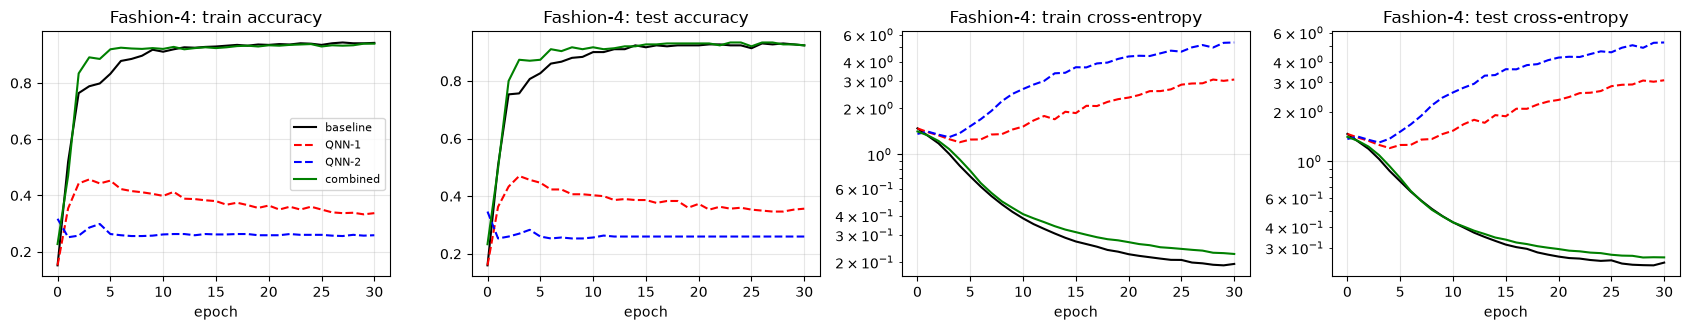

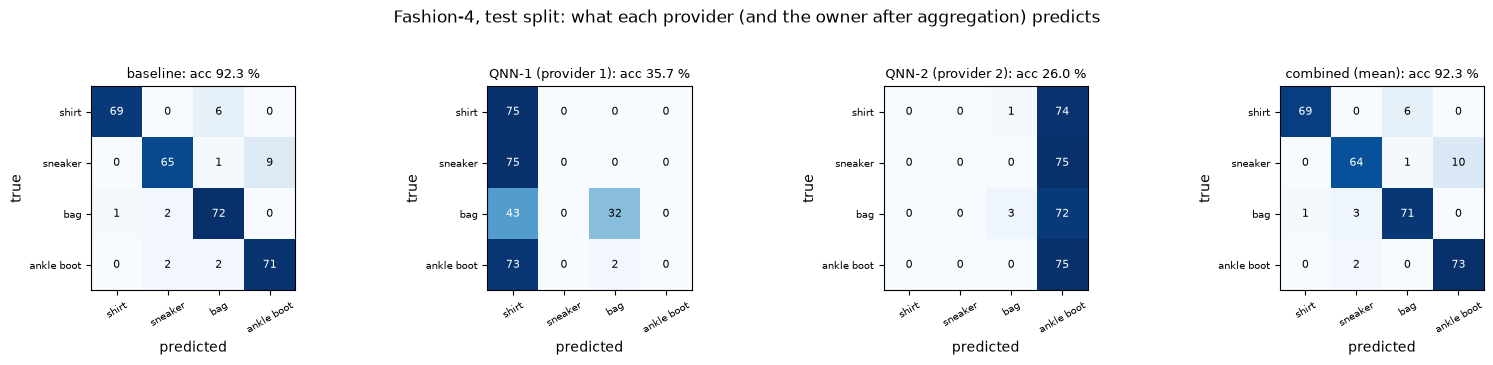

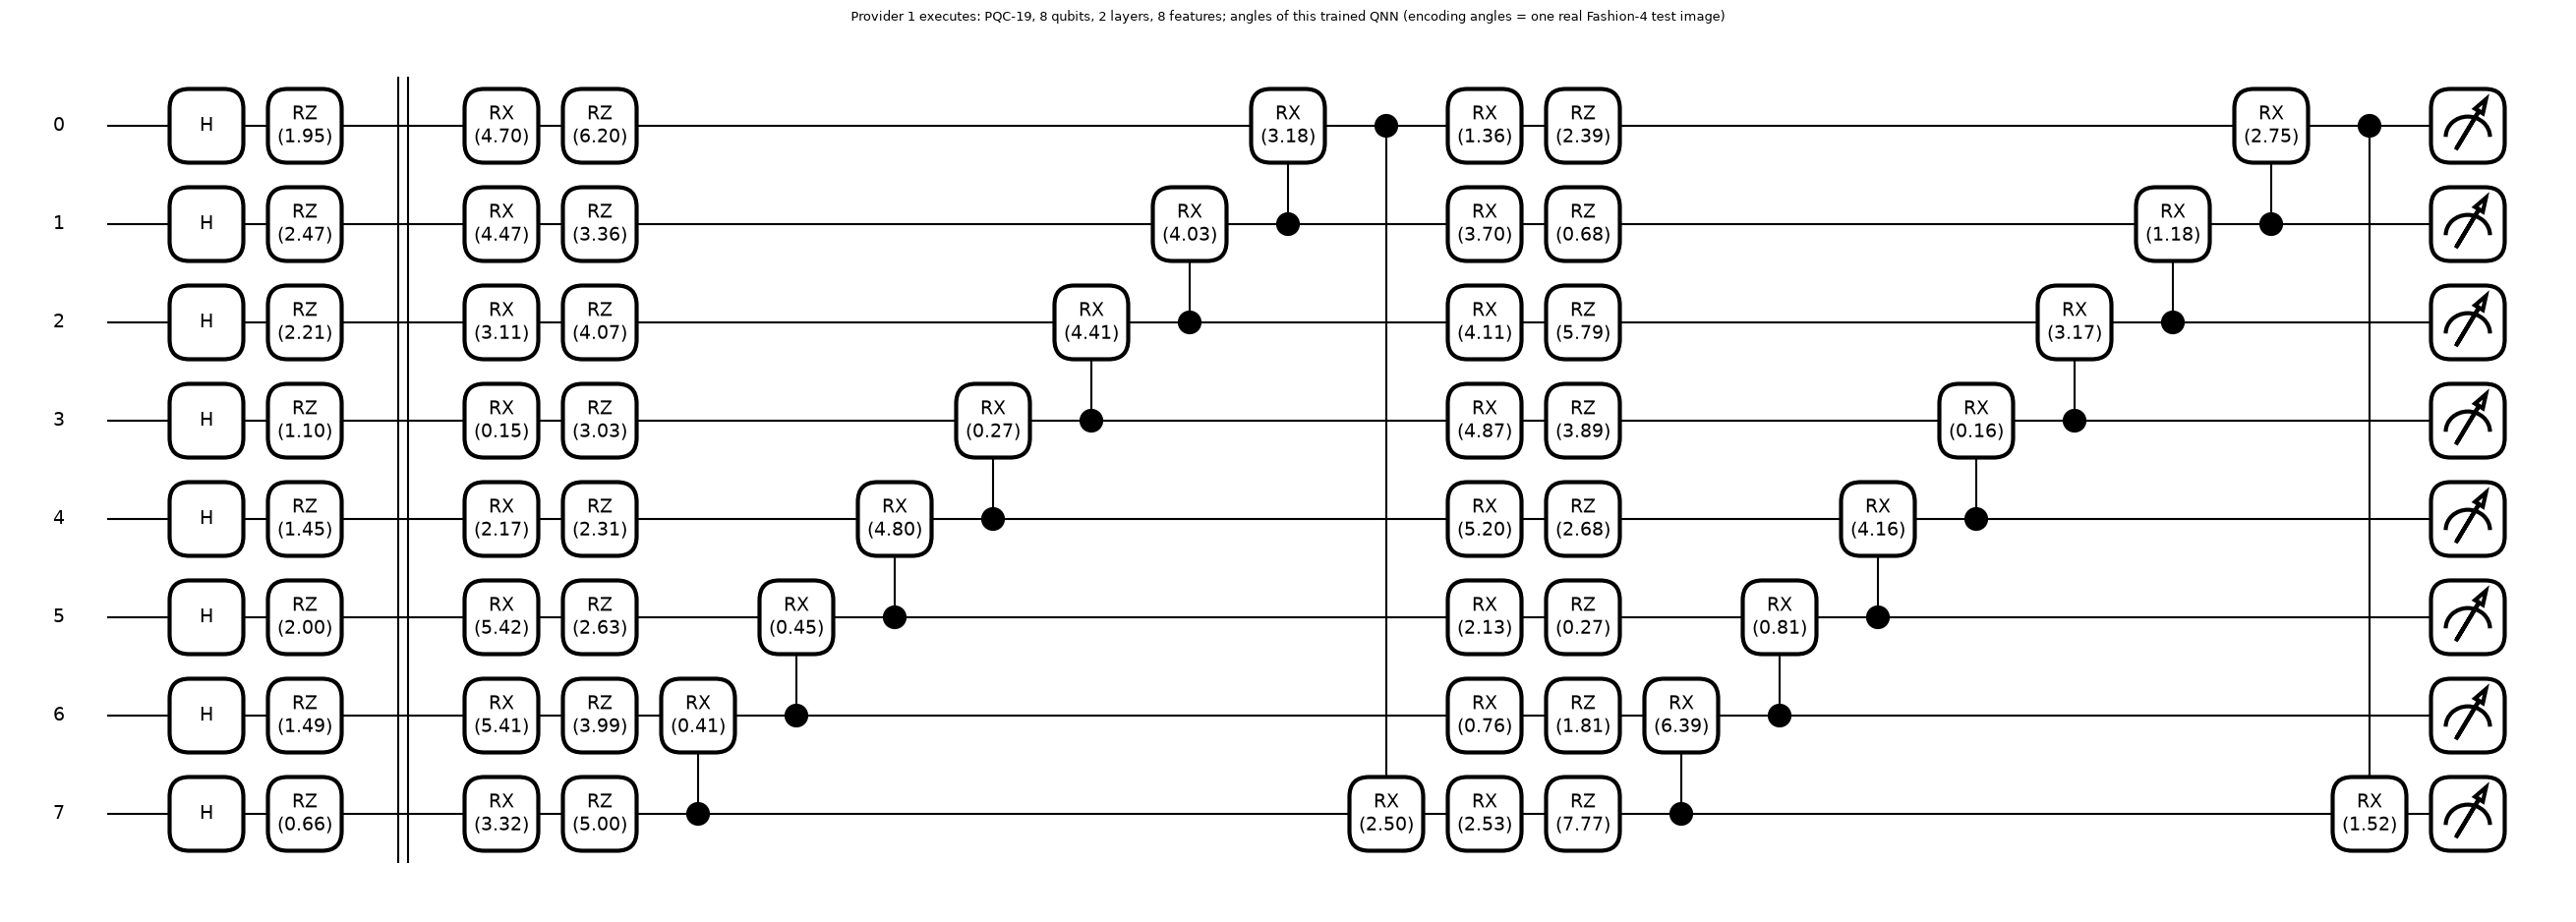

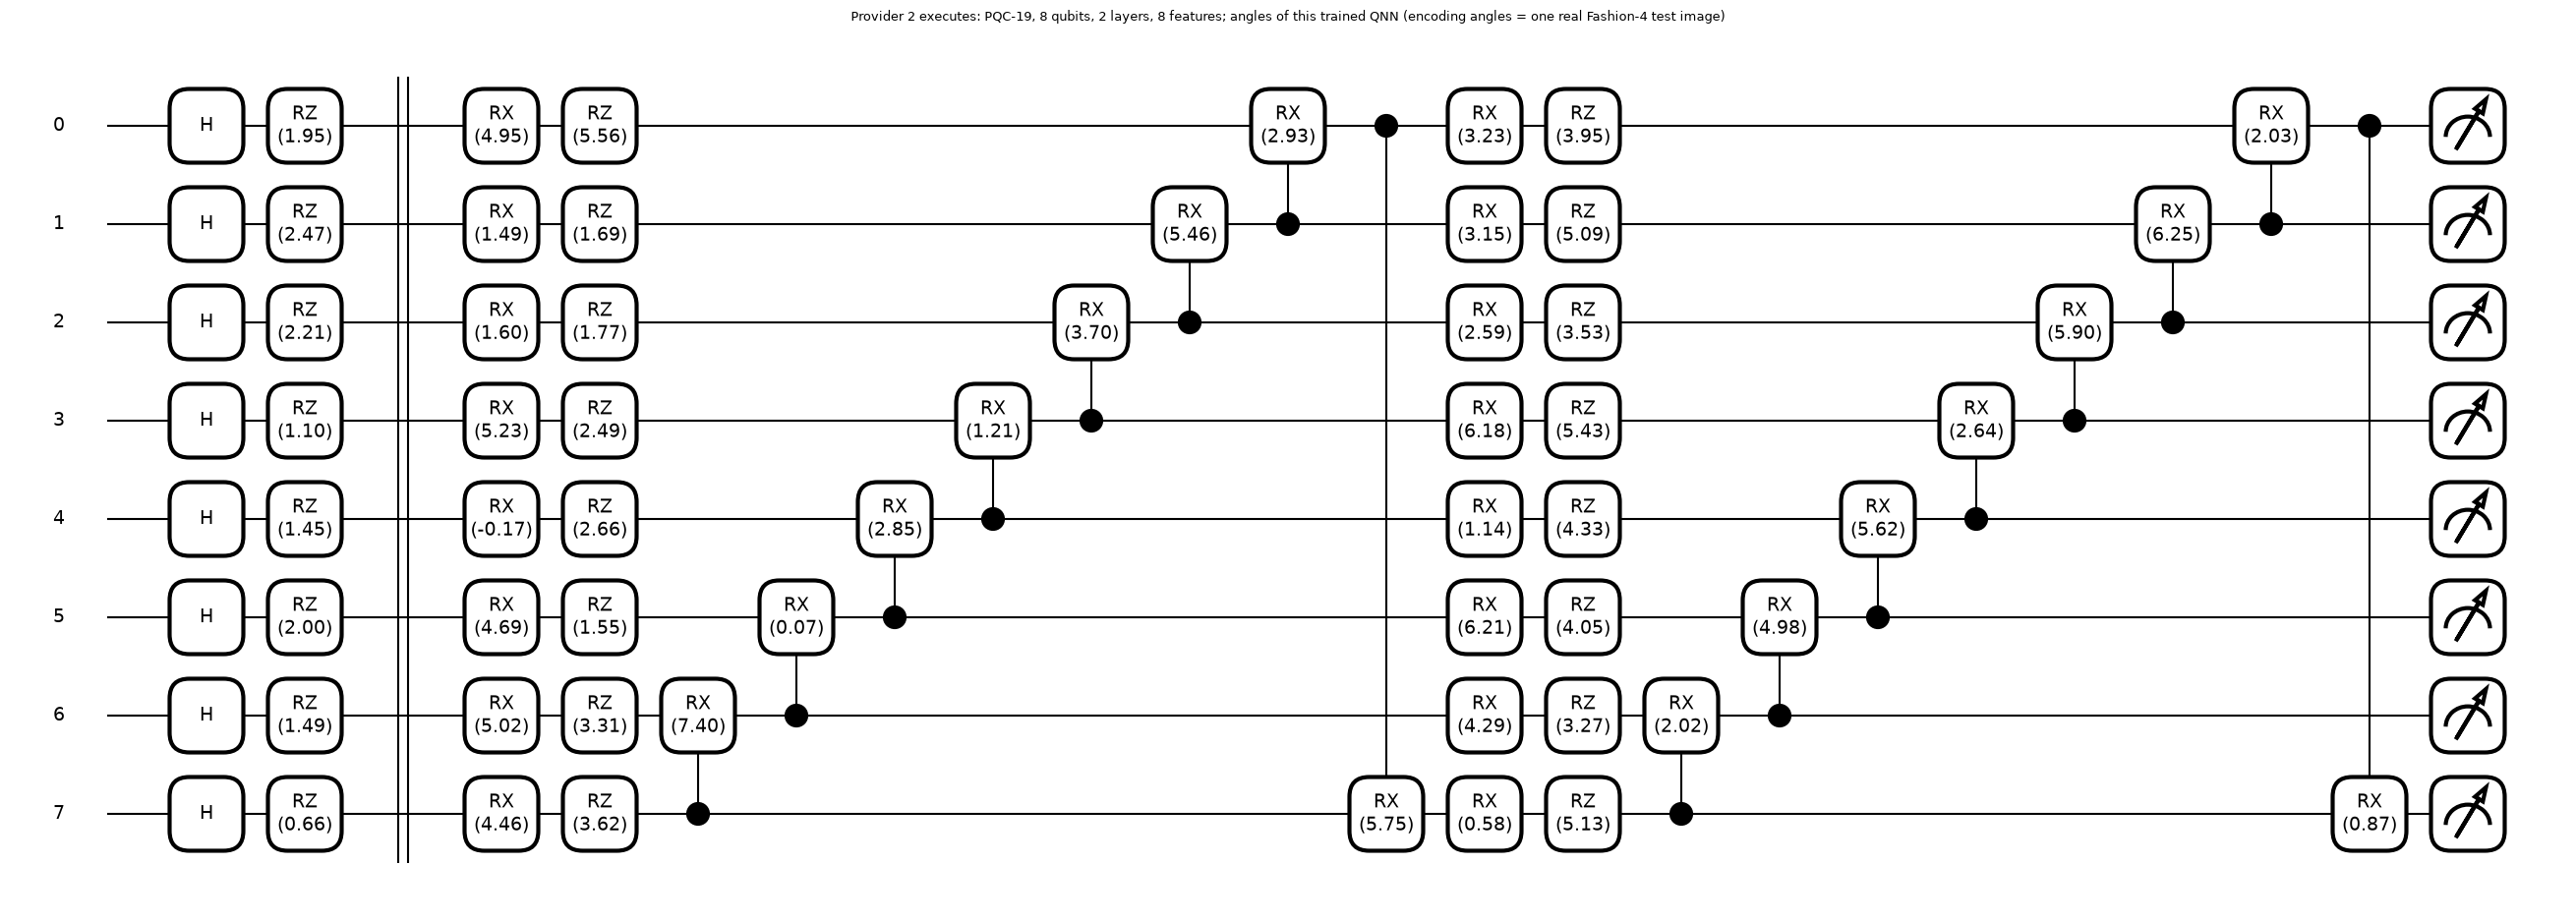

Both trained provider circuits reproduce the simulator output exactly (max difference < 1e-10).


In [14]:
sd0 = SEEDS[0]; sec = SEC_TASK
H_b, H_s = MAIN[(sec, sd0)]["base"]["hist"], MAIN[(sec, sd0)]["stiq"]["hist"]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.4))
for ax, (k, ttl) in zip(axes, [("train_acc", "train accuracy"), ("test_acc", "test accuracy"), ("train_loss", "train cross-entropy"), ("test_loss", "test cross-entropy")]):
    ax.plot(H_b["epoch"], H_b[f"{k}_0"], "k-", label="baseline"); ax.plot(H_s["epoch"], H_s[f"{k}_0"], "r--", label="QNN-1"); ax.plot(H_s["epoch"], H_s[f"{k}_1"], "b--", label="QNN-2"); ax.plot(H_s["epoch"], H_s[f"{k}_comb"], "g-", label="combined")
    ax.set_title(f"{sec}: {ttl}"); ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
    if "loss" in k: ax.set_yscale("log")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

# confusion matrices of QNN-1, QNN-2 and the aggregate against the true classes (test split of the first seed)
def pair_logits(res, dom):
    P = [encode_states(sp, dom["fte"]) for sp in res["specs"]]
    return [m.predict_logits(p) for m, p in zip(res["models"], P)]
d_sec = build_domain(sd0)[sec]; l1, l2 = pair_logits(MAIN[(sec, sd0)]["stiq"], d_sec); lb = pair_logits(MAIN[(sec, sd0)]["base"], d_sec)[0]
cls_names = [CLASS_NAMES[d_sec["src"]][c] for c in d_sec["orig_classes"]]
def conf(y, p, C=4):
    M = np.zeros((C, C), dtype=int)
    for a, b in zip(y, p): M[a, b] += 1
    return M
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, (ttl, lg) in zip(axes, [("baseline", lb), ("QNN-1 (provider 1)", l1), ("QNN-2 (provider 2)", l2), ("combined (mean)", (l1 + l2) / 2)]):
    M = conf(d_sec["yte"], lg.argmax(1).numpy()); ax.imshow(M, cmap="Blues")
    for i in range(4):
        for j in range(4): ax.text(j, i, M[i, j], ha="center", va="center", fontsize=8, color="w" if M[i, j] > M.max() / 2 else "k")
    ax.set_xticks(range(4)); ax.set_yticks(range(4)); ax.set_xticklabels(cls_names, rotation=30, fontsize=7); ax.set_yticklabels(cls_names, fontsize=7)
    ax.set_title(f"{ttl}: acc {100 * (M.trace() / M.sum()):.1f} %", fontsize=9); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.suptitle(f"{sec}, test split: what each provider (and the owner after aggregation) predicts", y=1.03); plt.tight_layout(); plt.show()

# the circuits that provider 1 and provider 2 execute: same architecture, different trained angles (rounded to 2 decimals); the QNode is the verified one of Section 2
st = MAIN[(sec, sd0)]["stiq"]; x_ex = d_sec["fte"][0]
for i, m in enumerate(st["models"]):
    th = m.theta.detach().numpy()
    fig, ax = qml.draw_mpl(make_qnode(m.spec), decimals=2, style="black_white")(x_ex, th)
    fig.suptitle(f"Provider {i + 1} executes: {m.spec.name}; angles of this trained QNN (encoding angles = one real {sec} test image)", fontsize=9, y=1.02); plt.show()
    z_pl = np.array([float(v) for v in make_qnode(m.spec)(x_ex, th)]); z_t = pqc_z(m.spec, encode_states(m.spec, x_ex[None]), m.theta.detach())[0].numpy()
    assert np.abs(z_pl - z_t).max() < 1e-10, "trained circuit: simulator and PennyLane disagree"
print("Both trained provider circuits reproduce the simulator output exactly (max difference < 1e-10).")

## 6. Penalty $\lambda$ and divergence function: Tables I and II, Figs. 5 and 6

**Table I / Fig. 5.** 4-qubit PQC-4 (1 layer), Fashion-4, cosine similarity, $\lambda \in \{0.1, 0.3, 0.5, 0.7, 0.9\}$ (`FAST_MODE` runs three of them). The paper's reading: larger $\lambda$ gives more obfuscation but costs combined accuracy; $[0.1, 0.3]$ is the sweet spot.

**Table II / Fig. 6.** Same 4-qubit model on MNIST-4 with $L_1$, $L_2$ and cosine similarity. The paper says $L_1$ and $L_2$ needed their own penalty values "determined empirically"; we pick them on a **validation split of the training data** (60 % / 40 % of the 700 training images, the test set is untouched) by maximising `validation combined accuracy - mean validation accuracy of the two members`.
We also run one **ablation** that the paper does not discuss: applying $A$ and $D$ to softmax probabilities instead of logits (the paper's Fig. 4 draws probability vectors).

seed 42 lambda=0.1: QNN-1 56.7 %, QNN-2 60.3 %, combined 90.0 % | baseline 89.7 %


seed 42 lambda=0.5: QNN-1 46.7 %, QNN-2 48.3 %, combined 87.0 % | baseline 89.7 %


seed 42 lambda=0.9: QNN-1 46.0 %, QNN-2 43.0 %, combined 86.3 % | baseline 89.7 %


done in 28 s

Table I (Fashion-4, 4 qubits). Baseline: notebook 89.7 %, paper 90.0 %
 lambda  QNN-1 (nb)  QNN-2 (nb)  combined (nb)  QNN-1 (paper)  QNN-2 (paper)  combined (paper)
    0.1        56.7        60.3           90.0           25.9           45.3              90.6
    0.5        46.7        48.3           87.0           39.6           25.6              86.0
    0.9        46.0        43.0           86.3           25.6           25.6              81.3


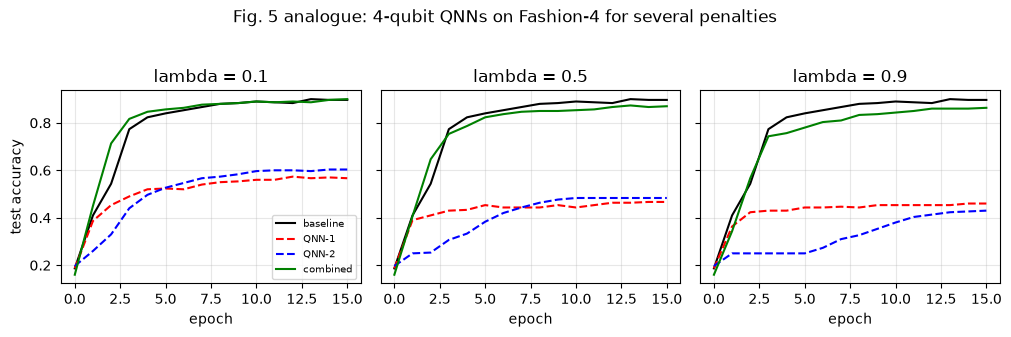

In [15]:
SPEC_T1 = ARCH_USES["Tables I-II (PQC-4)"]
T1 = {}      # (lam, seed) -> res ; 'base' per seed
t0 = time.time()
for seed in SEEDS:
    d = build_domain(seed)["Fashion-4"]
    T1[("base", seed)] = train([SPEC_T1], d, epochs=EPOCHS, seed=seed, tag="baseline T1")
    for lam in LAMBDAS:
        T1[(lam, seed)] = train([SPEC_T1, SPEC_T1], d, lam=lam, div="cos", epochs=EPOCHS, seed=seed, tag=f"STIQ lam={lam}")
        h = T1[(lam, seed)]["hist"].iloc[-1]
        print(f"seed {seed} lambda={lam}: QNN-1 {100*h['test_acc_0']:.1f} %, QNN-2 {100*h['test_acc_1']:.1f} %, combined {100*h['test_acc_comb']:.1f} % | baseline {100*T1[('base', seed)]['hist'].iloc[-1]['test_acc_0']:.1f} %", flush=True)
print(f"done in {time.time() - t0:.0f} s")

PAPER_T1 = {0.1: (25.9, 45.3, 90.6), 0.3: (25.6, 33.3, 89.3), 0.5: (39.6, 25.6, 86.0), 0.7: (25.6, 26.3, 83.9), 0.9: (25.6, 25.6, 81.3)}
rows = []; T1_NB = {}
for lam in LAMBDAS:
    a = np.array([[100 * T1[(lam, s)]["hist"].iloc[-1][k] for k in ("test_acc_0", "test_acc_1", "test_acc_comb")] for s in SEEDS]).mean(0)
    T1_NB[lam] = a; p = PAPER_T1[lam]
    rows.append({"lambda": lam, "QNN-1 (nb)": round(a[0], 1), "QNN-2 (nb)": round(a[1], 1), "combined (nb)": round(a[2], 1), "QNN-1 (paper)": p[0], "QNN-2 (paper)": p[1], "combined (paper)": p[2]})
T1_BASE = np.mean([100 * T1[("base", s)]["hist"].iloc[-1]["test_acc_0"] for s in SEEDS])
print(f"\nTable I (Fashion-4, 4 qubits). Baseline: notebook {T1_BASE:.1f} %, paper 90.0 %"); print(pd.DataFrame(rows).to_string(index=False))

fig, axes = plt.subplots(1, len(LAMBDAS), figsize=(3.4 * len(LAMBDAS), 3.2), sharey=True)
for ax, lam in zip(np.atleast_1d(axes), LAMBDAS):
    hb, hs = T1[("base", SEEDS[0])]["hist"], T1[(lam, SEEDS[0])]["hist"]
    ax.plot(hb["epoch"], hb["test_acc_0"], "k-", label="baseline"); ax.plot(hs["epoch"], hs["test_acc_0"], "r--", label="QNN-1"); ax.plot(hs["epoch"], hs["test_acc_1"], "b--", label="QNN-2"); ax.plot(hs["epoch"], hs["test_acc_comb"], "g-", label="combined")
    ax.set_title(f"lambda = {lam}"); ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
np.atleast_1d(axes)[0].set_ylabel("test accuracy"); np.atleast_1d(axes)[0].legend(fontsize=7); plt.suptitle("Fig. 5 analogue: 4-qubit QNNs on Fashion-4 for several penalties", y=1.04); plt.tight_layout(); plt.show()

  validation l1 lambda=0.01: combined 86.1 %, members 71.1 / 67.9 %, score 16.6


  validation l1 lambda=0.1: combined 74.3 %, members 44.6 / 41.4 %, score 31.2


  validation l2 lambda=0.01: combined 83.6 %, members 34.3 / 33.2 %, score 49.8


  validation l2 lambda=0.1: combined 25.0 %, members 30.7 / 28.9 %, score -4.8
CHOICE (validation on training data only): penalties {'cos': 0.3, 'l1': 0.1, 'l2': 0.01}


done in 61 s

Table II (MNIST-4, 4 qubits). Baseline: notebook 90.3 %, paper 91.6 %
                          divergence  lambda  QNN-1 (nb)  QNN-2 (nb)  combined (nb) QNN-1 (paper) QNN-2 (paper) combined (paper)
                                  L1    0.10        43.0        42.0           83.7          30.7          46.9             88.6
                                  L2    0.01        26.7        21.7           64.7          29.4          22.6             81.6
                    CosineSimilarity    0.30        46.3        41.0           91.7          31.9          40.3             91.3
Cosine on softmax outputs (ablation)    0.30        69.7        63.0           88.0             -             -                -


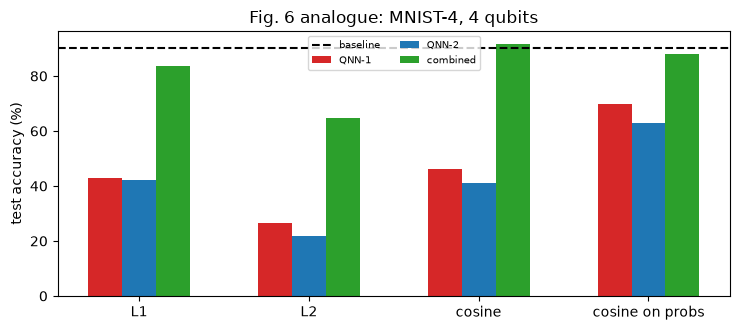

In [16]:
def subdomain(dom, idx_a, idx_b):
    """Split a task's TRAINING data into a fit part (a) and a validation part (b); the test split of `dom` is never touched."""
    return dict(dom, ftr=dom["ftr"][idx_a], ytr=dom["ytr"][idx_a], fte=dom["ftr"][idx_b], yte=dom["ytr"][idx_b])

T2 = {}; CHOSEN_LAM = {"cos": LAMBDA}; t0 = time.time()
d_t2 = build_domain(SEEDS[0])["MNIST-4"]
if True:
    ia, iv = train_test_split(np.arange(len(d_t2["ytr"])), test_size=0.4, stratify=d_t2["ytr"], random_state=SEEDS[0]); sub = subdomain(d_t2, ia, iv)
    for kind in ("l1", "l2"):
        best = None
        for lam in LAMBDA_GRID:
            r_ = train([SPEC_T1, SPEC_T1], sub, lam=lam, div=kind, epochs=EPOCHS, seed=SEEDS[0], tag=f"val {kind} {lam}"); h = r_["hist"].iloc[-1]
            score = h["test_acc_comb"] - (h["test_acc_0"] + h["test_acc_1"]) / 2      # 'test' here is the VALIDATION part of the training data
            print(f"  validation {kind} lambda={lam}: combined {100*h['test_acc_comb']:.1f} %, members {100*h['test_acc_0']:.1f} / {100*h['test_acc_1']:.1f} %, score {100*score:.1f}")
            if best is None or score > best[0]: best = (score, lam)
        CHOSEN_LAM[kind] = best[1]
print("CHOICE (validation on training data only): penalties", CHOSEN_LAM)

for seed in SEEDS:
    d = build_domain(seed)["MNIST-4"]
    T2[("base", seed)] = train([SPEC_T1], d, epochs=EPOCHS, seed=seed, tag="baseline T2")
    for kind in ("l1", "l2", "cos"):
        T2[(kind, seed)] = train([SPEC_T1, SPEC_T1], d, lam=CHOSEN_LAM[kind], div=kind, epochs=EPOCHS, seed=seed, tag=f"STIQ {kind}")
    T2[("cos-probs", seed)] = train([SPEC_T1, SPEC_T1], d, lam=CHOSEN_LAM["cos"], div="cos", epochs=EPOCHS, seed=seed, space="probs", tag="STIQ cos on probabilities")
print(f"done in {time.time() - t0:.0f} s")
PAPER_T2 = {"l1": (30.7, 46.9, 88.6), "l2": (29.4, 22.6, 81.6), "cos": (31.9, 40.3, 91.3)}
rows = []; T2_NB = {}
for kind in ("l1", "l2", "cos", "cos-probs"):
    a = np.array([[100 * T2[(kind, s)]["hist"].iloc[-1][k] for k in ("test_acc_0", "test_acc_1", "test_acc_comb")] for s in SEEDS]).mean(0); T2_NB[kind] = a
    p = PAPER_T2.get(kind, ("-", "-", "-")); lamv = CHOSEN_LAM.get(kind, CHOSEN_LAM["cos"])
    rows.append({"divergence": {"l1": "L1", "l2": "L2", "cos": "CosineSimilarity", "cos-probs": "Cosine on softmax outputs (ablation)"}[kind], "lambda": lamv, "QNN-1 (nb)": round(a[0], 1), "QNN-2 (nb)": round(a[1], 1), "combined (nb)": round(a[2], 1),
                 "QNN-1 (paper)": p[0], "QNN-2 (paper)": p[1], "combined (paper)": p[2]})
T2_BASE = np.mean([100 * T2[("base", s)]["hist"].iloc[-1]["test_acc_0"] for s in SEEDS])
print(f"\nTable II (MNIST-4, 4 qubits). Baseline: notebook {T2_BASE:.1f} %, paper 91.6 %"); print(pd.DataFrame(rows).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 3.4)); w = 0.2; xs = np.arange(4)
for j, (lab, col) in enumerate([("QNN-1", "tab:red"), ("QNN-2", "tab:blue"), ("combined", "tab:green")]):
    ax.bar(xs + (j - 1) * w, [T2_NB[k][j] for k in ("l1", "l2", "cos", "cos-probs")], w, color=col, label=lab)
ax.axhline(T2_BASE, color="k", ls="--", label="baseline"); ax.set_xticks(xs); ax.set_xticklabels(["L1", "L2", "cosine", "cosine on probs"]); ax.set_ylabel("test accuracy (%)"); ax.set_title("Fig. 6 analogue: MNIST-4, 4 qubits"); ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

## 7. Inference on simulated IBM devices: Table V and Fig. 8

The paper trains noiselessly and then **runs inference** with the trained angles on a `qiskit.aer` device that carries the noise model and native gates of a real IBM machine, in two set-ups:
(i) the baseline, QNN-1 and QNN-2 all run on **one** device (Sherbrooke); (ii) the three models run on **three different** devices (baseline on Sherbrooke, QNN-1 on Hanoi, QNN-2 on Cairo), which is the realistic "two untrusted clouds" case.

Here the Qiskit circuit of Section 2 (angles fixed to the trained values, the 8 image features left as parameters) is transpiled in two steps: first routed onto a chain of 8 connected, low-readout-error physical qubits of the device and translated to its native gates, then placed on the full device with that layout.
It is then executed with `NoiseModel.from_backend(...)` on Aer's density-matrix simulator with 1000 shots per image; $\langle Z_q\rangle$ is estimated from the counts and fed to the (classical) linear layer.
The devices are the fake backends shipped with `qiskit-ibm-runtime` (`FakeSherbrooke`, `FakeHanoiV2`, `FakeCairoV2`): snapshots of the real devices' calibration data, so no account is needed.

In [17]:
from qiskit import transpile
from qiskit.circuit import ParameterVector
from qiskit.transpiler import CouplingMap
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_ibm_runtime.fake_provider import FakeSherbrooke, FakeHanoiV2, FakeCairoV2
import qiskit, qiskit_aer
print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__)

_BK = {}
def get_backend(name):
    if name not in _BK:
        be = {"Sherbrooke": FakeSherbrooke, "Hanoi": FakeHanoiV2, "Cairo": FakeCairoV2}[name]()
        _BK[name] = (be, AerSimulator(noise_model=NoiseModel.from_backend(be), method="density_matrix"))
    return _BK[name]

def find_path(be, n):
    """CHOICE: a chain of n coupled physical qubits, found by depth-first search that prefers qubits with the lowest read-out error."""
    err = lambda q: (be.target["measure"][(q,)].error or 0.0) if "measure" in be.target.operation_names else 0.0
    adj = {}
    for a, b in be.coupling_map.get_edges(): adj.setdefault(a, set()).add(b); adj.setdefault(b, set()).add(a)
    def dfs(path):
        if len(path) == n: return path
        for nb in sorted(adj[path[-1]] - set(path), key=err):
            r = dfs(path + [nb])
            if r: return r
        return None
    for s in sorted(adj, key=err):
        r = dfs([s])
        if r: return r
    raise RuntimeError("no chain found")

def transpile_for_device(spec, theta, be, seed):
    xs = ParameterVector("x", spec.d); qc = qiskit_circuit(spec, xs, theta, barrier=False); qc.measure_all()
    path = find_path(be, spec.n); edges = set(be.coupling_map.get_edges())
    local = [(i, j) for i, a in enumerate(path) for j, b in enumerate(path) if (a, b) in edges]          # directed edges of the chain, as the device supports them
    basis = [g for g in ("rz", "sx", "x", "ecr", "cx") if g in be.operation_names]
    qc1 = transpile(qc, basis_gates=basis, coupling_map=CouplingMap(local), optimization_level=1, seed_transpiler=seed)      # route on the chain + native gates
    qc2 = transpile(qc1, be, initial_layout=path, optimization_level=0, seed_transpiler=seed)                                 # place on the device, fix gate directions
    return xs, qc2, path

def device_z(spec, theta, X, dev_name, shots=SHOTS, seed=SEED):
    """<Z_q> estimated from `shots` noisy executions of the trained circuit on a simulated IBM device, for every row of X."""
    be, sim = get_backend(dev_name); xs, qc, path = transpile_for_device(spec, theta, be, seed)
    circs = [qc.assign_parameters(dict(zip(xs, [float(v) for v in row]))) for row in X]
    res = sim.run(circs, shots=shots, seed_simulator=seed).result(); Z = np.zeros((len(X), spec.n))
    for i in range(len(X)):
        for bits, c in res.get_counts(i).items():
            b = bits.replace(" ", "")[::-1]                                  # b[q] = measured bit of logical qubit q
            Z[i] += c * np.array([1 - 2 * int(b[q]) for q in range(spec.n)])
    return Z / shots, qc

# one transpiled circuit, for the record
_be, _ = get_backend("Sherbrooke"); _m = MAIN[(sorted({t for t, _ in MAIN})[0], SEEDS[0])]["base"]["models"][0]
_, _qc, _path = transpile_for_device(_m.spec, _m.theta.detach().numpy(), _be, SEED)
_ops = _qc.count_ops(); print(f"Sherbrooke, chain {_path}: transpiled depth {_qc.depth()}, native gates {dict(_ops)}")

qiskit 2.5.2 | qiskit-aer 0.17.2


Sherbrooke, chain [74, 89, 88, 87, 93, 106, 105, 104]: transpiled depth 250, native gates {'rz': 247, 'sx': 171, 'ecr': 74, 'x': 17, 'measure': 8, 'barrier': 1}


Letters-4: baseline circuit on Sherbrooke: transpiled depth 250, 74 ECR gates; mean |<Z>_noisy - <Z>_ideal| = 0.089, mean |<Z>_ideal| = 0.351


Letters-4: done (36 s elapsed)



Notebook, accuracy (%) on 40 test images (paper: 300 images), 1000 shots per image:
  dataset                          set-up  baseline  QNN-1  QNN-2  combined
Letters-4             noiseless simulator      85.0   20.0   27.5      82.5
Letters-4           (i) all on Sherbrooke      77.5   20.0   25.0      85.0
Letters-4 (ii) Sherbrooke / Hanoi / Cairo      77.5   20.0   22.5      42.5

Paper, Table V (set-up ii):
  dataset  baseline  QNN-1  QNN-2  combined
Letters-4      91.0   37.0   21.0      91.0


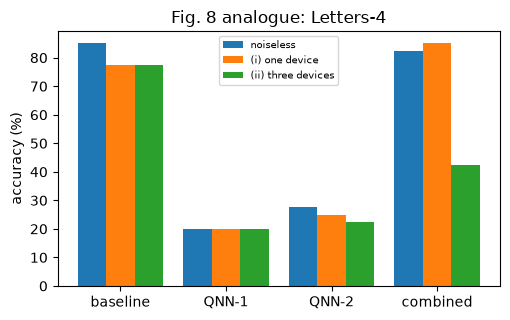

In [18]:
PAPER_T5 = {"MNIST-4": (97.0, 22.6, 38.3, 97.3), "Fashion-4": (95.0, 37.3, 40.1, 95.0), "Kuzushiji-4": (86.6, 44.0, 27.3, 87.6), "Letters-4": (91.0, 37.0, 21.0, 91.0)}
NOISY = {}; t0 = time.time(); rows = []
for t in NOISY_TASKS:
    d = build_domain(SEEDS[0])[t]; sel = np.random.default_rng(SEEDS[0]).permutation(len(d["yte"]))[:NOISY_IMAGES]; Xn, yn = d["fte"][sel], torch.as_tensor(d["yte"][sel])
    base, st = MAIN[(t, SEEDS[0])]["base"]["models"][0], MAIN[(t, SEEDS[0])]["stiq"]["models"]
    def noisy_logits(m, dev): z, _ = device_z(m.spec, m.theta.detach().numpy(), Xn, dev); return m.logits_from_z(torch.as_tensor(z)).detach()
    def ideal_logits(m): return m.predict_logits(encode_states(m.spec, Xn))
    acc = lambda l: 100 * float((l.argmax(1) == yn).double().mean())
    ideal = dict(base=acc(ideal_logits(base)), q1=acc(ideal_logits(st[0])), q2=acc(ideal_logits(st[1])), comb=acc((ideal_logits(st[0]) + ideal_logits(st[1])) / 2))
    zb, qcb = device_z(base.spec, base.theta.detach().numpy(), Xn, "Sherbrooke"); lb = base.logits_from_z(torch.as_tensor(zb)).detach()
    zi = pqc_z_nograd(base.spec, encode_states(base.spec, Xn), base.theta.detach()).numpy()
    print(f"{t}: baseline circuit on Sherbrooke: transpiled depth {qcb.depth()}, {qcb.count_ops().get('ecr', 0)} ECR gates; mean |<Z>_noisy - <Z>_ideal| = {np.abs(zb - zi).mean():.3f}, mean |<Z>_ideal| = {np.abs(zi).mean():.3f}")
    l1s, l2s = noisy_logits(st[0], "Sherbrooke"), noisy_logits(st[1], "Sherbrooke"); l1h, l2c = noisy_logits(st[0], "Hanoi"), noisy_logits(st[1], "Cairo")
    NOISY[t] = {"ideal": ideal, "one": dict(base=acc(lb), q1=acc(l1s), q2=acc(l2s), comb=acc((l1s + l2s) / 2)), "three": dict(base=acc(lb), q1=acc(l1h), q2=acc(l2c), comb=acc((l1h + l2c) / 2))}
    for k, nm in (("ideal", "noiseless simulator"), ("one", "(i) all on Sherbrooke"), ("three", "(ii) Sherbrooke / Hanoi / Cairo")):
        v = NOISY[t][k]; rows.append({"dataset": t, "set-up": nm, "baseline": round(v["base"], 1), "QNN-1": round(v["q1"], 1), "QNN-2": round(v["q2"], 1), "combined": round(v["comb"], 1)})
    print(f"{t}: done ({time.time() - t0:.0f} s elapsed)", flush=True)
print(f"\nNotebook, accuracy (%) on {NOISY_IMAGES} test images (paper: 300 images), 1000 shots per image:"); print(pd.DataFrame(rows).to_string(index=False))
print("\nPaper, Table V (set-up ii):"); print(pd.DataFrame([{"dataset": t, "baseline": v[0], "QNN-1": v[1], "QNN-2": v[2], "combined": v[3]} for t, v in PAPER_T5.items() if t in NOISY_TASKS]).to_string(index=False))

fig, axes = plt.subplots(1, len(NOISY_TASKS), figsize=(5.2 * len(NOISY_TASKS), 3.3), squeeze=False)
for ax, t in zip(axes[0], NOISY_TASKS):
    for j, (k, ttl) in enumerate([("ideal", "noiseless"), ("one", "(i) one device"), ("three", "(ii) three devices")]):
        v = NOISY[t][k]; ax.bar(np.arange(4) + (j - 1) * 0.27, [v["base"], v["q1"], v["q2"], v["comb"]], 0.27, label=ttl)
    ax.set_xticks(range(4)); ax.set_xticklabels(["baseline", "QNN-1", "QNN-2", "combined"]); ax.set_ylabel("accuracy (%)"); ax.set_title(f"Fig. 8 analogue: {t}"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 8. Real quantum hardware: Table VI

The paper runs 4-qubit, 2-layer PQC-1 models for Letters-4 on IBM Kyoto, Brisbane and Sherbrooke. Kyoto and Brisbane are no longer available and running on a real device needs your own IBM account, so this cell only runs if you set `IBM_TOKEN` in the configuration cell; otherwise the claim is reported as **cannot be checked**.
(The branch below has not been executed in the notebook's validation run, because no token was supplied.)

In [19]:
HARDWARE = None
if not IBM_TOKEN:
    print("IBM_TOKEN is empty: the real-hardware experiment (Table VI) is skipped. Paper: Letters-4, 4 qubits, 2 layers PQC-1, IBM Kyoto: baseline 89.0, QNN-1 40.0, QNN-2 20.0, combined 88.0 (accuracy %).")
else:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=IBM_TOKEN); be = service.least_busy(operational=True, simulator=False, min_num_qubits=16)
    sp6 = ARCH_USES["Table VI (PQC-1)"]; d6 = build_domain(SEEDS[0])["Letters-4"]; n_img = 20
    base6 = train([sp6], d6, epochs=EPOCHS, seed=SEEDS[0]); pair6 = train([sp6, sp6], d6, lam=LAMBDA, epochs=EPOCHS, seed=SEEDS[0])
    sampler = SamplerV2(mode=be); out = {}
    for nm, m in (("baseline", base6["models"][0]), ("QNN-1", pair6["models"][0]), ("QNN-2", pair6["models"][1])):
        xs, qc, path = transpile_for_device(sp6, m.theta.detach().numpy(), be, SEEDS[0])
        pubs = [(qc, [float(v) for v in row]) for row in d6["fte"][:n_img]]
        res = sampler.run(pubs, shots=SHOTS).result(); Z = np.zeros((n_img, sp6.n))
        for i, r_ in enumerate(res):
            for bits, c in r_.data.meas.get_counts().items():
                b = bits[::-1]; Z[i] += c * np.array([1 - 2 * int(b[q]) for q in range(sp6.n)])
        out[nm] = m.logits_from_z(torch.as_tensor(Z / SHOTS)).detach()
    yh = torch.as_tensor(d6["yte"][:n_img]); a = lambda l: 100 * float((l.argmax(1) == yh).double().mean())
    HARDWARE = dict(backend=be.name, baseline=a(out["baseline"]), q1=a(out["QNN-1"]), q2=a(out["QNN-2"]), comb=a((out["QNN-1"] + out["QNN-2"]) / 2)); print(HARDWARE)

IBM_TOKEN is empty: the real-hardware experiment (Table VI) is skipped. Paper: Letters-4, 4 qubits, 2 layers PQC-1, IBM Kyoto: baseline 89.0, QNN-1 40.0, QNN-2 20.0, combined 88.0 (accuracy %).


## 9. Scaling to MNIST-10 with SPSA (Table VII) and the cost of a smaller pair (Fig. 9, overhead)

**Table VII.** 2-layer QNNs with 4, 8, (12, 16) qubits on a 10-class MNIST task of 2000 samples (70 / 30), gradients by **SPSA** (zero-order, as would be needed on hardware) combined with Adam. The paper reports that STIQ's combined accuracy *exceeds* the baseline by up to 6 points.
We use one feature per qubit (PCA to as many components as qubits). The budgets (qubit counts, epochs) are in the configuration cell: 16 qubits is left out because one SPSA step of a 16-qubit, batch-32 state vector takes minutes on a CPU.

**Fig. 9 / overhead.** STIQ trains two QNNs, i.e. about twice the circuit evaluations. The paper argues that smaller members (4-qubit PQC-6) reduce the cost at about 2.5 points of accuracy, compared with an 8-qubit PQC-8 baseline on Kuzushiji-4. We train that comparison and measure the wall-clock overhead.

In [20]:
PAPER_T7 = {4: (57.2, 22.3, 11.1, 65.3), 8: (69.1, 8.33, 20.5, 75.5), 12: (89.6, 21.5, 10.0, 93.0), 16: (85.5, 13.8, 14.3, 90.5)}
SCALE = {}; t0 = time.time(); rows = []
for nq in SCALE_QUBITS:
    sp = Spec(nq, nq, 19, 2); d = build_mnist10(SEEDS[0], nq)
    rb = train([sp], d, epochs=SCALE_EPOCHS, seed=SEEDS[0], grad="spsa", tag=f"MNIST-10 baseline {nq}q")
    rs = train([sp, sp], d, lam=LAMBDA, div="cos", epochs=SCALE_EPOCHS, seed=SEEDS[0], grad="spsa", tag=f"MNIST-10 STIQ {nq}q")
    SCALE[nq] = dict(base=rb, stiq=rs); hb, hs = rb["hist"].iloc[-1], rs["hist"].iloc[-1]; p = PAPER_T7[nq]
    rows.append({"qubits": nq, "baseline (nb)": round(100 * hb["test_acc_0"], 1), "QNN-1 (nb)": round(100 * hs["test_acc_0"], 1), "QNN-2 (nb)": round(100 * hs["test_acc_1"], 1), "combined (nb)": round(100 * hs["test_acc_comb"], 1),
                 "baseline (paper)": p[0], "QNN-1 (paper)": p[1], "QNN-2 (paper)": p[2], "combined (paper)": p[3], "seconds base / STIQ": f"{rb['seconds']:.0f} / {rs['seconds']:.0f}"})
    print(f"{nq} qubits done ({time.time() - t0:.0f} s elapsed)", flush=True)
print("\nTable VII analogue (MNIST-10, SPSA + Adam, %d epochs; chance = 10 %%):" % SCALE_EPOCHS); print(pd.DataFrame(rows).to_string(index=False))

4 qubits done (17 s elapsed)


8 qubits done (61 s elapsed)



Table VII analogue (MNIST-10, SPSA + Adam, 6 epochs; chance = 10 %):
 qubits  baseline (nb)  QNN-1 (nb)  QNN-2 (nb)  combined (nb)  baseline (paper)  QNN-1 (paper)  QNN-2 (paper)  combined (paper) seconds base / STIQ
      4           41.3        15.8        20.2           42.3              57.2          22.30           11.1              65.3              6 / 11
      8           60.2        18.0        24.8           63.7              69.1           8.33           20.5              75.5             14 / 29


                        acc  acc1  acc2  acc_comb  seconds
baseline 8q PQC-8      83.7   NaN   NaN       NaN     39.4
STIQ pair of 4q PQC-6   NaN  38.3  44.7      83.3     49.8


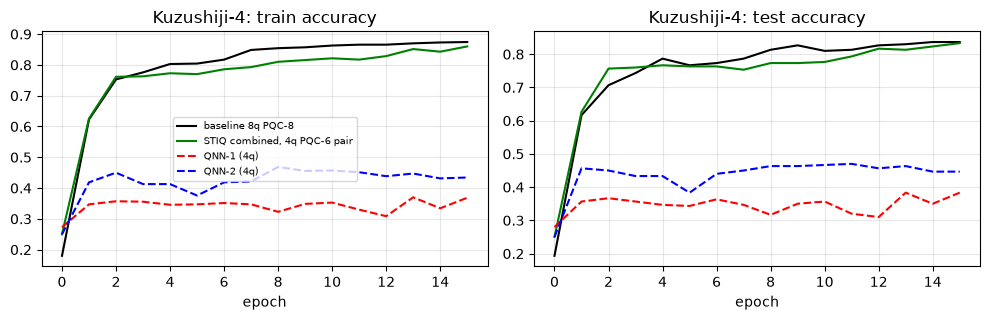


Training wall-clock of the STIQ pair / one baseline (same architecture, same epochs; PennyLane-free simulator): mean 2.05x over 4 runs. Circuit evaluations: exactly 2x.


In [21]:
# ---- Fig. 9: one 8-qubit PQC-8 baseline against a pair of 4-qubit PQC-6 members, Kuzushiji-4 ----
d9 = build_domain(SEEDS[0])["Kuzushiji-4"]; sp_big, sp_small = ARCH_USES["Fig. 9 baseline (PQC-8)"], ARCH_USES["Fig. 9 STIQ member (PQC-6)"]
r9b = train([sp_big], d9, epochs=EPOCHS, seed=SEEDS[0], tag="Fig9 baseline 8q PQC-8")
r9s = train([sp_small, sp_small], d9, lam=LAMBDA, epochs=EPOCHS, seed=SEEDS[0], tag="Fig9 STIQ 4q PQC-6")
FIG9 = {k: final_row(v) for k, v in {"baseline 8q PQC-8": r9b, "STIQ pair of 4q PQC-6": r9s}.items()}
print(pd.DataFrame(FIG9).T[["acc", "acc1", "acc2", "acc_comb", "seconds"]].round(1).to_string())
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
for ax, k, ttl in zip(axes, ("train", "test"), ("train accuracy", "test accuracy")):
    ax.plot(r9b["hist"]["epoch"], r9b["hist"][f"{k}_acc_0"], "k-", label="baseline 8q PQC-8"); ax.plot(r9s["hist"]["epoch"], r9s["hist"][f"{k}_acc_comb"], "g-", label="STIQ combined, 4q PQC-6 pair")
    ax.plot(r9s["hist"]["epoch"], r9s["hist"][f"{k}_acc_0"], "r--", label="QNN-1 (4q)"); ax.plot(r9s["hist"]["epoch"], r9s["hist"][f"{k}_acc_1"], "b--", label="QNN-2 (4q)")
    ax.set_title(f"Kuzushiji-4: {ttl}"); ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

ov = []
for t in TASKS:
    for s in SEEDS: ov.append(dict(task=t, seed=s, ratio=MAIN[(t, s)]["stiq"]["seconds"] / MAIN[(t, s)]["base"]["seconds"]))
OVERHEAD = pd.DataFrame(ov).ratio.mean()
print(f"\nTraining wall-clock of the STIQ pair / one baseline (same architecture, same epochs; PennyLane-free simulator): mean {OVERHEAD:.2f}x over {len(ov)} runs. Circuit evaluations: exactly 2x.")

## 10. What can a thief actually do? Measuring the paper's security analysis

The paper argues qualitatively: (a) one stolen QNN is useless because its answers are wrong; (b) two stolen QNNs are useless unless the thief also knows the secret aggregation function. We measure this on one dataset (`SEC_TASK`, first seed), always next to the same attack on the **unprotected** baseline.
Throughout, the thief is generous: it knows the architecture, sees the exact output vectors (no shot noise) and tests on the victim's own test images.

| Attack | What the thief has | How success is measured |
|---|---|---|
| A0. Use the stolen model as is | circuit angles and classical layer of one provider | test accuracy |
| A1. Black-box clone | 700 unlabeled queries sent to one hosted model, its answers (softmax of the output vector) | clone trained on (query, answer), test accuracy on true labels and fidelity (agreement with the victim) |
| A2. Two providers, guessed aggregator | outputs of both providers for the test images, no knowledge of $A$ | accuracy of each plausible aggregator |
| A3. Stolen circuit, new classical head | the quantum circuit of one provider + a few labelled images | logistic regression on the circuit's $\langle Z\rangle$ values (does the circuit still carry the class information?) |
| A4. Fine-tune stolen weights | trained angles of one provider + a few labelled images | accuracy after a few epochs, against training from scratch |

Query sets for A1: **mixed** (unlabeled images from the *other three* tasks, "non-problem-domain") and **in-domain** (unlabeled training images of the victim's task, the strongest case).

In [22]:
sd0 = SEEDS[0]; sec = SEC_TASK; D_SEC = build_domain(sd0)[sec]
base_m = MAIN[(sec, sd0)]["base"]["models"][0]; q1_m, q2_m = MAIN[(sec, sd0)]["stiq"]["models"]
Xte, yte_t = D_SEC["fte"], torch.as_tensor(D_SEC["yte"]); psi_te = encode_states(base_m.spec, Xte)
VICT = {"unprotected baseline": base_m, "STIQ provider 1": q1_m, "STIQ provider 2": q2_m}
def service(m, X): return F.softmax(m.predict_logits(encode_states(m.spec, X)), 1)          # what a hosted model answers (exact probabilities)
acc_of = lambda lg: 100 * float((lg.argmax(1) == yte_t).double().mean())

def fit_soft(model, X, T, epochs, seed):
    """Train `model` (a Hybrid) on soft targets T with Adam (cross-entropy with soft labels = KL divergence up to a constant)."""
    psi = encode_states(model.spec, X); opt = torch.optim.Adam(model.params(), lr=LR); r = np.random.default_rng(seed)
    for ep in range(epochs):
        perm = r.permutation(len(X))
        for s in range(0, len(X), BATCH):
            i = torch.as_tensor(perm[s:s + BATCH]); opt.zero_grad()
            loss = -(T[i] * F.log_softmax(model.logits(psi[i]), 1)).sum(1).mean(); loss.backward(); opt.step()
    return model

# ---- query sets ----
others = [d["pool"] for t, d in build_domain(sd0).items() if t != sec]
Q_MIX = np.concatenate(others)[np.random.default_rng(sd0).permutation(sum(len(o) for o in others))[:700]]       # 700 unlabeled non-problem-domain queries
Q_DOM = D_SEC["ftr"]                                                                                                # 700 unlabeled in-domain queries (labels never used)

rows = []; CLONES = {}
for vn, vm in VICT.items():
    row = {"victim": vn, "A0 stolen model acc": acc_of(vm.predict_logits(psi_te))}
    vpred = vm.predict_logits(psi_te).argmax(1)
    for qn, Q in (("mixed", Q_MIX), ("in-domain", Q_DOM)):
        cl = fit_soft(Hybrid(vm.spec, 4, sd0 * 100 + 50), Q, service(vm, Q), SEC_EPOCHS, sd0)
        lg = cl.predict_logits(psi_te); CLONES[(vn, qn)] = cl
        row[f"A1 clone acc ({qn})"] = acc_of(lg); row[f"A1 fidelity ({qn})"] = 100 * float((lg.argmax(1) == vpred).double().mean())
    rows.append(row)
A01 = pd.DataFrame(rows).set_index("victim").round(1)
print(f"Dataset {sec}; chance level about 25 %. Test accuracies (%) of the thief's model on the victim's 300 test images:"); print(A01.to_string())

Dataset Fashion-4; chance level about 25 %. Test accuracies (%) of the thief's model on the victim's 300 test images:
                      A0 stolen model acc  A1 clone acc (mixed)  A1 fidelity (mixed)  A1 clone acc (in-domain)  A1 fidelity (in-domain)
victim                                                                                                                                 
unprotected baseline                 92.3                  78.0                 84.3                      90.7                     97.7
STIQ provider 1                      35.7                  29.0                 89.7                      34.7                     95.7
STIQ provider 2                      26.0                  25.0                 98.7                      25.0                     98.7


A2. Accuracy of the plausible aggregation functions applied to the two providers' outputs:
                                  accuracy (%)
provider 1 alone                          35.7
provider 2 alone                          26.0
mean of outputs (the paper's A)           92.3
sum of outputs                            92.3
mean of softmax probabilities             49.7
element-wise max of outputs               51.7
element-wise min of outputs               51.0
product of softmax probabilities          92.3
difference y1 - y2                        25.0



A3. Accuracy (%) after fitting a NEW linear head on the stolen circuit's <Z> values with n labelled images:
                                    20 labels  100 labels  700 labels
stolen circuit                                                       
unprotected baseline circuit             91.3        92.3        93.0
STIQ provider 1 circuit                  84.3        88.0        89.7
STIQ provider 2 circuit                  86.0        88.3        90.3
both STIQ circuits (concatenated)        91.3        90.7        92.7
random untrained circuit (control)       69.7        80.3        86.7



A4. Fine-tuning with 100 labelled images (60 epochs): accuracy before / after (%)
                             before  after
from scratch (random init)     32.7   90.3
init = unprotected baseline    92.3   90.7
init = STIQ provider 1         35.7   89.3
init = STIQ provider 2         26.0   88.3


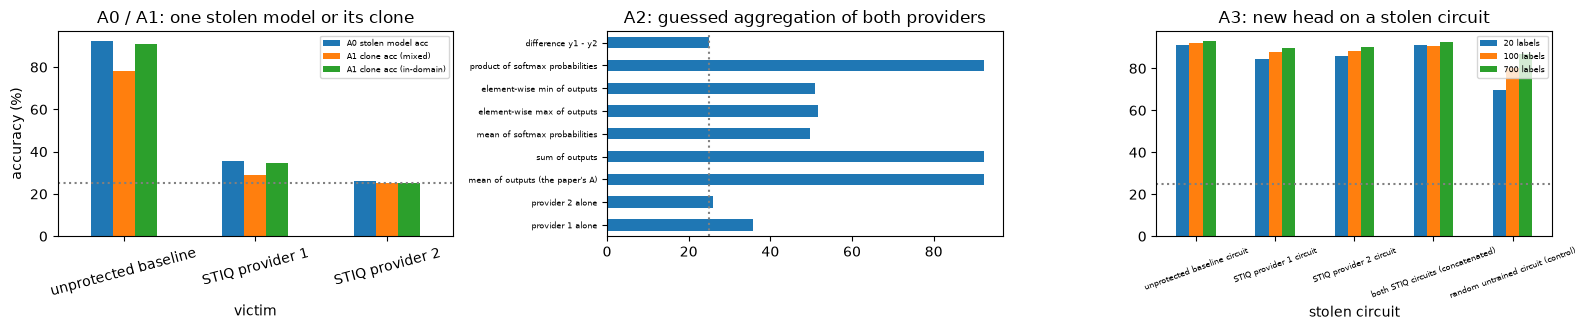

In [23]:
# ---- A2: both providers are compromised, the thief does not know the aggregation function ----
l1 = q1_m.predict_logits(psi_te); l2 = q2_m.predict_logits(psi_te); p1, p2 = F.softmax(l1, 1), F.softmax(l2, 1)
AGG = {"provider 1 alone": l1, "provider 2 alone": l2, "mean of outputs (the paper's A)": (l1 + l2) / 2, "sum of outputs": l1 + l2, "mean of softmax probabilities": (p1 + p2) / 2,
       "element-wise max of outputs": torch.maximum(l1, l2), "element-wise min of outputs": torch.minimum(l1, l2), "product of softmax probabilities": p1 * p2, "difference y1 - y2": l1 - l2}
A2 = pd.Series({k: acc_of(v) for k, v in AGG.items()}).round(1).to_frame("accuracy (%)")
print("A2. Accuracy of the plausible aggregation functions applied to the two providers' outputs:"); print(A2.to_string())

# ---- A3: stolen circuit + new classical head fitted on a few labelled images ----
from sklearn.linear_model import LogisticRegression
def z_feats(m, X): return pqc_z_nograd(m.spec, encode_states(m.spec, X), m.theta.detach()).numpy()
rnd_m = Hybrid(base_m.spec, 4, sd0 * 100 + 77)              # control: an UNTRAINED random circuit of the same architecture
r = np.random.default_rng(sd0); lab_idx = {n_lab: np.concatenate([r.choice(np.where(D_SEC["ytr"] == c)[0], min(n_lab // 4, int((D_SEC["ytr"] == c).sum())), replace=False) for c in range(4)]) for n_lab in (20, 100, 700)}
rows = []
for nm, ms in {"unprotected baseline circuit": [base_m], "STIQ provider 1 circuit": [q1_m], "STIQ provider 2 circuit": [q2_m], "both STIQ circuits (concatenated)": [q1_m, q2_m], "random untrained circuit (control)": [rnd_m]}.items():
    Ztr = np.hstack([z_feats(m, D_SEC["ftr"]) for m in ms]); Zte = np.hstack([z_feats(m, Xte) for m in ms]); row = {"stolen circuit": nm}
    for n_lab, ix in lab_idx.items(): row[f"{n_lab} labels"] = 100 * LogisticRegression(max_iter=2000).fit(Ztr[ix], D_SEC["ytr"][ix]).score(Zte, D_SEC["yte"])
    rows.append(row)
A3 = pd.DataFrame(rows).set_index("stolen circuit").round(1)
print("\nA3. Accuracy (%) after fitting a NEW linear head on the stolen circuit's <Z> values with n labelled images:"); print(A3.to_string())

# ---- A4: fine-tune stolen weights with 100 labelled images vs training from scratch ----
ix = lab_idx[100]; T_lab = F.one_hot(torch.as_tensor(D_SEC["ytr"][ix]), 4).double(); rows = {}
for nm, src in {"from scratch (random init)": None, "init = unprotected baseline": base_m, "init = STIQ provider 1": q1_m, "init = STIQ provider 2": q2_m}.items():
    m = Hybrid(base_m.spec, 4, sd0 * 100 + 90)
    if src is not None: m.load(src.clone_params())
    a0 = acc_of(m.predict_logits(psi_te)); fit_soft(m, D_SEC["ftr"][ix], T_lab, FT_EPOCHS * 10, sd0)       # 100 images, batch 32: about 4 steps per epoch, so scale epochs by 10
    rows[nm] = dict(before=a0, after=acc_of(m.predict_logits(psi_te)))
A4 = pd.DataFrame(rows).T.round(1)
print(f"\nA4. Fine-tuning with 100 labelled images ({FT_EPOCHS * 10} epochs): accuracy before / after (%)"); print(A4.to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
a = A01[["A0 stolen model acc", "A1 clone acc (mixed)", "A1 clone acc (in-domain)"]]; a.plot.bar(ax=axes[0], rot=15); axes[0].axhline(25, color="grey", ls=":"); axes[0].set_ylabel("accuracy (%)"); axes[0].set_title("A0 / A1: one stolen model or its clone"); axes[0].legend(fontsize=6)
A2["accuracy (%)"].plot.barh(ax=axes[1]); axes[1].axvline(25, color="grey", ls=":"); axes[1].set_title("A2: guessed aggregation of both providers"); axes[1].tick_params(axis="y", labelsize=6)
A3.plot.bar(ax=axes[2], rot=20); axes[2].axhline(25, color="grey", ls=":"); axes[2].set_title("A3: new head on a stolen circuit"); axes[2].legend(fontsize=6); axes[2].tick_params(axis="x", labelsize=6)
plt.tight_layout(); plt.show()

## 11. Side by side with the paper: one verdict per claim

Rules (fixed before looking at the numbers): an accuracy is **reproduced** if it lies within 2 percentage points of the paper's value, otherwise **not reached** (lower) or **exceeded** (higher) with the gap; qualitative claims get **reproduced** when the stated inequality holds in this notebook.
"Obfuscated" means: the mean accuracy of QNN-1 and QNN-2 is at most half of the baseline's. Anything the notebook cannot run is **cannot be checked**. All notebook numbers are test accuracies (%) from this run (mean over the seeds in `SEEDS`).

In [24]:
CLAIMS = []
def add(source, claim, paper, nb, verdict): CLAIMS.append({"source": source, "claim": claim, "paper": paper, "this notebook": nb, "verdict": verdict})
def acc_verdict(p, n, tol=2.0):
    d = n - p
    return "reproduced" if abs(d) <= tol else (f"exceeded (+{d:.1f})" if d > 0 else f"not reached ({d:.1f})")

mean_over = lambda f: float(np.mean([f(s) for s in SEEDS]))
# ---- Tables III / IV ----
for t in TASKS:
    pb, _, p1, _, p2, _, pc, _ = PAPER_T3[t]
    nb_b = mean_over(lambda s: final_row(MAIN[(t, s)]["base"])["acc"]); nb_1 = mean_over(lambda s: final_row(MAIN[(t, s)]["stiq"])["acc1"])
    nb_2 = mean_over(lambda s: final_row(MAIN[(t, s)]["stiq"])["acc2"]); nb_c = mean_over(lambda s: final_row(MAIN[(t, s)]["stiq"])["acc_comb"])
    add("Table III", f"{t}: baseline accuracy", f"{pb}", f"{nb_b:.1f}", acc_verdict(pb, nb_b))
    add("Table III", f"{t}: combined (STIQ) accuracy", f"{pc}", f"{nb_c:.1f}", acc_verdict(pc, nb_c))
    add("Tables III/IV", f"{t}: members obfuscated (mean of QNN-1, QNN-2 <= 0.5 x baseline)", f"{p1} / {p2} (ratio {(p1 + p2) / 2 / pb:.2f})", f"{nb_1:.1f} / {nb_2:.1f} (ratio {(nb_1 + nb_2) / 2 / nb_b:.2f})", "reproduced" if (nb_1 + nb_2) / 2 <= 0.5 * nb_b else "not reached")
    add("Table IV", f"{t}: combined within 2 points of own baseline", f"{pc - pb:+.1f}", f"{nb_c - nb_b:+.1f}", "reproduced" if nb_c >= nb_b - 2 else f"not reached ({nb_c - nb_b:.1f})")
# ---- Table I ----
for lam in LAMBDAS:
    p = PAPER_T1[lam][2]; n_ = T1_NB[lam][2]; add("Table I", f"4 qubits, Fashion-4, lambda={lam}: combined accuracy", f"{p}", f"{n_:.1f}", acc_verdict(p, n_))
add("Table I", "baseline accuracy (4 qubits, Fashion-4)", "90.0", f"{T1_BASE:.1f}", acc_verdict(90.0, T1_BASE))
comb = [T1_NB[l][2] for l in LAMBDAS]
add("Table I / Fig. 5", "combined accuracy falls as lambda grows", "90.6 -> 81.3 (monotone)", " -> ".join(f"{c:.1f}" for c in comb), "reproduced" if comb[0] >= comb[-1] + 1 else "not reached")
mem_hi = (T1_NB[LAMBDAS[-1]][0] + T1_NB[LAMBDAS[-1]][1]) / 2
add("Table I / Fig. 5", f"members near chance (25 %) at lambda={LAMBDAS[-1]}", "25.6 / 25.6", f"{T1_NB[LAMBDAS[-1]][0]:.1f} / {T1_NB[LAMBDAS[-1]][1]:.1f}", "reproduced" if mem_hi <= 35 else "not reached")
# ---- Table II ----
for kind, nm in (("l1", "L1"), ("l2", "L2"), ("cos", "CosineSimilarity")):
    p = PAPER_T2[kind][2]; n_ = T2_NB[kind][2]; add("Table II", f"MNIST-4, {nm}: combined accuracy", f"{p}", f"{n_:.1f}", acc_verdict(p, n_))
add("Table II", "baseline accuracy (4 qubits, MNIST-4)", "91.6", f"{T2_BASE:.1f}", acc_verdict(91.6, T2_BASE))
add("Table II / Fig. 6", "cosine similarity gives the best combined accuracy of the three", "91.3 > 88.6 > 81.6", f"{T2_NB['cos'][2]:.1f} / {T2_NB['l1'][2]:.1f} / {T2_NB['l2'][2]:.1f}", "reproduced" if T2_NB["cos"][2] >= max(T2_NB["l1"][2], T2_NB["l2"][2]) else "not reached")
# ---- Table V ----
for t in NOISY_TASKS:
    v, p = NOISY[t]["three"], PAPER_T5[t]
    add("Table V", f"{t}: noisy devices (ii), combined within 2 points of the noisy baseline", f"{p[3] - p[0]:+.1f}", f"{v['comb'] - v['base']:+.1f} ({NOISY_IMAGES} images)", "reproduced" if v["comb"] >= v["base"] - 2 else f"not reached ({v['comb'] - v['base']:.1f})")
    add("Table V", f"{t}: noisy devices, members obfuscated", f"{p[1]} / {p[2]}", f"{v['q1']:.1f} / {v['q2']:.1f}", "reproduced" if (v["q1"] + v["q2"]) / 2 <= 0.5 * v["base"] else "not reached")
    add("Table V", f"{t}: noisy baseline accuracy", f"{p[0]}", f"{v['base']:.1f}", acc_verdict(p[0], v["base"], 2.0 if NOISY_IMAGES >= 300 else 8.0))
# ---- Table VI ----
if HARDWARE is None: add("Table VI", "real IBM hardware (Kyoto, Brisbane, Sherbrooke)", "baseline 89-90, combined 88-90, members 40 / 20", "not run (no IBM_TOKEN; devices partly retired)", "cannot be checked")
else: add("Table VI", f"real hardware ({HARDWARE['backend']})", "baseline 89-90, combined 88-90", f"baseline {HARDWARE['baseline']:.0f}, combined {HARDWARE['comb']:.0f}, members {HARDWARE['q1']:.0f} / {HARDWARE['q2']:.0f}", "reproduced" if HARDWARE["comb"] >= HARDWARE["baseline"] - 5 else "not reached")
# ---- Table VII ----
for nq in SCALE_QUBITS:
    hb, hs = SCALE[nq]["base"]["hist"].iloc[-1], SCALE[nq]["stiq"]["hist"].iloc[-1]; p = PAPER_T7[nq]
    b_, c_ = 100 * hb["test_acc_0"], 100 * hs["test_acc_comb"]; m_ = 100 * (hs["test_acc_0"] + hs["test_acc_1"]) / 2
    add("Table VII", f"MNIST-10, {nq} qubits: STIQ combined >= baseline", f"{p[3]} vs {p[0]}", f"{c_:.1f} vs {b_:.1f}", "reproduced" if c_ >= b_ else f"not reached ({c_ - b_:.1f})")
    add("Table VII", f"MNIST-10, {nq} qubits: members obfuscated", f"{p[1]} / {p[2]}", f"{100 * hs['test_acc_0']:.1f} / {100 * hs['test_acc_1']:.1f}", "reproduced" if m_ <= 0.5 * b_ else "not reached")
    add("Table VII", f"MNIST-10, {nq} qubits: baseline accuracy (absolute)", f"{p[0]}", f"{b_:.1f}", acc_verdict(p[0], b_))
# ---- Fig 9 and overhead ----
gap = FIG9["baseline 8q PQC-8"]["acc"] - FIG9["STIQ pair of 4q PQC-6"]["acc_comb"]
add("Fig. 9", "pair of 4-qubit PQC-6 loses about 2.5 points against an 8-qubit PQC-8 baseline (Kuzushiji-4)", "about -2.5", f"{-gap:+.1f}", "reproduced" if abs(gap - 2.5) <= 2.0 else ("exceeded (smaller loss)" if gap < 0.5 else f"not reached (loss {gap:.1f})"))
add("Overhead", "training cost at most about 2x", "<= 2x", f"{OVERHEAD:.2f}x wall-clock, 2x circuit evaluations", "reproduced" if OVERHEAD <= 2.3 else "not reached")
# ---- security analysis (qualitative in the paper, measured here) ----
b_acc = A01.loc["unprotected baseline", "A0 stolen model acc"]
for pv in ("STIQ provider 1", "STIQ provider 2"):
    best_clone = A01.loc[pv, ["A0 stolen model acc", "A1 clone acc (mixed)", "A1 clone acc (in-domain)"]].max()
    add("Sec. V-D (a)", f"{pv}: stolen model and its black-box clones are useless (best <= 0.5 x baseline)", "useless", f"best {best_clone:.1f} vs baseline {b_acc:.1f}", "reproduced" if best_clone <= 0.5 * b_acc else "not reached")
agg_best = A2.drop(["provider 1 alone", "provider 2 alone"]).iloc[:, 0].max(); agg_name = A2.drop(["provider 1 alone", "provider 2 alone"]).iloc[:, 0].idxmax()
add("Sec. V-D (b)", "both providers stolen: useless without the secret aggregation function", "useless", f"'{agg_name}' reaches {agg_best:.1f} % (baseline {b_acc:.1f} %)", "reproduced" if agg_best <= 0.5 * b_acc else "not reached (the natural guess recovers the model)")
a3 = A3.loc["STIQ provider 1 circuit", "100 labels"], A3.loc["random untrained circuit (control)", "100 labels"]
add("beyond the paper", "stolen provider circuit + new head fitted on 100 labels vs a random circuit", "not discussed", f"{a3[0]:.1f} vs {a3[1]:.1f} (baseline circuit {A3.loc['unprotected baseline circuit', '100 labels']:.1f})", "cannot be checked (not in paper)")
CLAIM_TAB = pd.DataFrame(CLAIMS)
print(CLAIM_TAB.to_string(index=False, max_colwidth=82))
vc = CLAIM_TAB.verdict.str.extract(r"^(reproduced|not reached|exceeded|cannot be checked)")[0].fillna("other").value_counts(); print("\nVerdict counts:", {k: int(v) for k, v in vc.items()})

           source                                                                              claim                                           paper                                                      this notebook                                            verdict
        Table III                                                         MNIST-4: baseline accuracy                                            98.3                                                               95.3                                 not reached (-3.0)
        Table III                                                  MNIST-4: combined (STIQ) accuracy                                            98.3                                                               93.3                                 not reached (-5.0)
    Tables III/IV               MNIST-4: members obfuscated (mean of QNN-1, QNN-2 <= 0.5 x baseline)                        22.6 / 37.6 (ratio 0.31)                                           53.3 / 2

In [25]:
print(f"Total run time of this notebook: {(time.time() - T_NOTEBOOK_START) / 60:.1f} minutes (FAST_MODE={FAST_MODE}, epochs={EPOCHS}, main tables {EPOCHS_MAIN}, seeds={SEEDS}).")
print("Budgets of the full run (FAST_MODE=False): 30 epochs, 3 seeds, lambda in {0.1, 0.3, 0.5, 0.7, 0.9}, 4 datasets x 100 noisy images, MNIST-10 with 4 / 8 / 12 qubits x 30 SPSA epochs, clones 25 epochs.")

Total run time of this notebook: 24.2 minutes (FAST_MODE=True, epochs=15, main tables 30, seeds=[42]).
Budgets of the full run (FAST_MODE=False): 30 epochs, 3 seeds, lambda in {0.1, 0.3, 0.5, 0.7, 0.9}, 4 datasets x 100 noisy images, MNIST-10 with 4 / 8 / 12 qubits x 30 SPSA epochs, clones 25 epochs.


## 12. Reading the paper critically

*(Written after the executed run of this notebook (FAST_MODE, one seed); the numbers quoted refer to its outputs. If you change the seed or budgets, re-read the tables before trusting the sentences.)*

1. **What the split really protects.** STIQ makes the *answers* of each provider misleading, and that part works as described: the members' mean accuracy is about 0.33-0.43 times the baseline on all four datasets (Table IV analogue), the combined output matches the baseline within about 2 points, and black-box clones trained on a provider's answers stay at that provider's weak accuracy (A1), while the same attack on the unprotected model reaches 78-91 %. But the **circuits are not worthless**: fitting a new linear head on a stolen provider circuit with only 20 labelled images gives 84-86 % (A3, Fashion-4), against about 70 % for an untrained random circuit and 91 % for the unprotected circuit. The decoy is in the classical output layer and in the *difference* of the two outputs, not in the quantum features.
2. **The secret aggregation function is obscurity.** If both providers are compromised, the paper's own choice (mean, equivalent to the sum) recovers the baseline accuracy exactly (A2), and so does the product of softmax probabilities. A thief that knows the paper, or tries the few standard aggregators on a handful of labelled images, wins. Aggregators that do not preserve the logit-level cancellation (element-wise max/min, mean of probabilities) give only about 50 %.
3. **A thief with labelled data does not need the model.** In A4, 100 labelled images fine-tune a *random* QNN to about 90 %, the same as when starting from the unprotected model's weights; the stolen STIQ weights give no advantage either. STIQ protects against a thief without labels (the model-extraction threat of the paper), not against one who can label a few hundred images himself; the classical SVC / forest / MLP baselines of Section 4 reach 83-96 % on the very same 8 numbers.
4. **Obfuscation is learned, not guaranteed, and it is asymmetric.** With cosine similarity on logits the optimiser ends in a state where one provider (QNN-2) answers a constant class in most runs (25 % on balanced classes) and the other carries more of the information (35-53 %). This is far from the paper's tables where both members are in the 22-44 % range; whether the paper's runs are symmetric cannot be told from its single numbers.
5. **Choices that the paper leaves open matter.** Applying $A$ and $D$ to probabilities instead of logits removes the obfuscation (members 63-70 %, Table II ablation); $L_2$ with a penalty that is too large collapses the combined accuracy (12.7 % at $\lambda = 0.1$ in an earlier run, chosen away by the validation grid here); the order of the controlled-`RX` gates, the encoding of 8 numbers on 4 qubits and the autoencoder are unspecified. Our absolute accuracies are 3-5 points below the paper's for MNIST-4, Fashion-4 and Kuzushiji-4 and 12 points below for Letters-4, which is the feature extractor (PCA instead of a convolutional autoencoder; an SVC on the same numbers gives 83 % for Letters-4) rather than the quantum part.
6. **Noise breaks the cancellation when the providers differ.** The paper reports no loss on noisy devices. Here, with all three models on one simulated device (Sherbrooke) the combined output kept up with the baseline, but with the realistic split over three devices (Sherbrooke / Hanoi / Cairo) the combined accuracy fell to about 43 % (40 images, standard error about 8 points, one dataset). That is what the mechanism would predict: the decoy terms $\pm d$ of the two outputs only cancel if both are computed accurately, and different noise models perturb them differently. The experiment must be repeated with more images and all datasets (`FAST_MODE = False`) before this is more than a warning.
7. **Statistics.** The paper reports single runs on 300 test images (one image = 0.33 points); differences of 1 point, such as "combined 95.9 vs baseline 95.6", are inside the noise. FAST_MODE here also uses one seed; the full mode repeats Tables III-IV over three seeds.
8. **Scalability claim.** "STIQ outperforms the baseline by up to 6 %" on MNIST-10 (Table VII) compares an SPSA-trained single model with two jointly trained models of the same size, i.e. twice the parameters and twice the circuit evaluations. In our short SPSA runs the combined output was only 1-4 points above the baseline; the paper does not control for the doubled budget.
9. **Real hardware.** Table VI cannot be repeated (devices retired / no token), and the paper does not give the number of test images or shots per image for it.

## 13. Exercises

1. **Longer training.** Set `EPOCHS = 30` and `SEEDS = [42, 43, 44]` for Table III only. How many epochs does it take until the mean accuracy of QNN-1 and QNN-2 falls below half the baseline's? Plot the curves of Section 5.1.
2. **Three providers.** Extend `total_loss` to three members with aggregation `mean` and divergence = the mean pairwise cosine similarity. Does the pair-wise obfuscation get stronger or weaker? What does a thief with two of the three models learn?
3. **Break the aggregator.** In Section 10 (A2), give the thief 20 labelled images and let it choose among the aggregators of the table. How often does it pick the right one? Which aggregator would you use to make this harder, and does it cost accuracy?
4. **Shot noise for the thief.** In A1 the thief sees exact probabilities. Replace `service` by a 1000-shot estimate of $\langle Z\rangle$ (see Section 7) and measure how much the clone accuracy of the *unprotected* model drops. Does the defence still look necessary?
5. **Different members.** Train STIQ with QNN-1 = PQC-19 and QNN-2 = PQC-4 (different architectures, as the paper suggests when it speaks of "different hardware"). Does obfuscation or combined accuracy change? Draw both circuits with `qml.draw_mpl`.